# Subset of the Lending Club Dataset

In [10]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import (train_test_split, cross_val_score, cross_validate,
    cross_val_predict, GridSearchCV, RandomizedSearchCV, StratifiedKFold)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet, LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix, make_scorer)

In [113]:
import shutil
from pathlib import Path

# Copy dataset files from sample_data folder to the current working directory
source_train = Path('/content/sample_data/loan_sample_train.csv')
source_test = Path('/content/sample_data/loan_sample_test.csv')

if source_train.exists():
    shutil.copy(source_train, './loan_sample_train.csv')
    print("Successfully copied train dataset to current working directory.")
else:
    print("Train dataset not found in sample_data.")

if source_test.exists():
    shutil.copy(source_test, './loan_sample_test.csv')
    print("Successfully copied test dataset to current working directory.")
else:
    print("Test dataset not found in sample_data.")

Successfully copied train dataset to current working directory.
Successfully copied test dataset to current working directory.


In [114]:
# Load and reconstruct the necessary splits (X_train, X_test, y_train, y_test)
train = pd.read_csv('loan_sample_train.csv')
test = pd.read_csv('loan_sample_test.csv')

train['dataset_type'] = 'train'
test['dataset_type'] = 'test'
loan = pd.concat([train, test], ignore_index=True)

# Prepare target column
loan['target'] = loan['loan_status'].apply(lambda x: 1 if x == 'Charged Off' else 0)

# Drop high correlation features
def drop_high_corr(df, threshold=0.8):
    corr_matrix = df.select_dtypes(include='number').drop(columns='target', errors='ignore').corr().abs()
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    to_drop = upper.columns[upper.gt(threshold).any()].tolist()
    return df.drop(columns=to_drop)

loan = drop_high_corr(loan)

# Clean up according to configuration defined in previous notebook cells
columns_to_drop = [
    'id', 'member_id', 'url', 'policy_code', 'application_type', 'disbursement_method',
    'initial_list_status', 'emp_title', 'desc', 'title', 'funded_amnt', 'funded_amnt_inv',
    'installment', 'hardship_payoff_balance_amount', 'settlement_amount', 'FICO_scores',
    'grade', 'zip_code', 'loan_status', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp',
    'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee',
    'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d', 'last_credit_pull_d', 'hardship_flag',
    'debt_settlement_flag', 'out_prncp', 'out_prncp_inv'
]

def removing_highnull_features(df, percent):
    max_nulls = df.shape[0] * percent
    col_to_drop = [col for col in df.columns if df[col].isnull().sum() > max_nulls]
    return df.drop(columns=col_to_drop)

loan_clean = removing_highnull_features(loan, 0.65)
loan_final = loan_clean.drop(columns=[col for col in columns_to_drop if col in loan_clean.columns])

# Transform dates and categorical strings
def transform_earliest_cr_line(df, cr_col='earliest_cr_line', issue_col='issue_d'):
    df[cr_col] = pd.to_datetime(df[cr_col], format='%b-%Y', errors='coerce')
    df[issue_col] = pd.to_datetime(df[issue_col], format='%b-%Y', errors='coerce')
    df['credit_history_years'] = df[issue_col].dt.year - df[cr_col].dt.year
    return df.drop([cr_col, issue_col], axis=1)

loan_final = transform_earliest_cr_line(loan_final)
loan_final['term'] = loan_final['term'].str.strip().replace({'36 months': 36, '60 months': 60})

# Manual ordinal encoding
cleaner_app_type = {
    'sub_grade': {"A1": 1.0, "A2": 2.0, "A3": 3.0, "A4": 4.0, "A5": 5.0, "B1": 11.0, "B2": 12.0, "B3": 13.0, "B4": 14.0, "B5": 15.0, "C1": 21.0, "C2": 22.0, "C3": 23.0, "C4": 24.0, "C5": 25.0, "D1": 31.0, "D2": 32.0, "D3": 33.0, "D4": 34.0, "D5": 35.0, "E1": 41.0, "E2": 42.0, "E3": 43.0, "E4": 44.0, "E5": 45.0, "F1": 51.0, "F2": 52.0, "F3": 53.0, "F4": 54.0, "F5": 55.0, "G1": 61.0, "G2": 62.0, "G3": 63.0, "G4": 64.0, "G5": 65.0},
    'emp_length': {"< 1 year": 0.0, '1 year': 1.0, '2 years': 2.0, '3 years': 3.0, '4 years': 4.0, '5 years': 5.0, '6 years': 6.0, '7 years': 7.0, '8 years': 8.0, '9 years': 9.0, '10+ years': 10.0}
}
loan_final = loan_final.replace(cleaner_app_type)

# One-Hot Encoding
cat_columns = loan_final.select_dtypes(object).columns
loans_final_encoded = pd.get_dummies(loan_final, prefix_sep="__", columns=cat_columns)
loans_final_encoded = loans_final_encoded.dropna()

# Separate back to train/test
train_set = loans_final_encoded[loans_final_encoded['dataset_type__train'] == True]
test_set = loans_final_encoded[loans_final_encoded['dataset_type__test'] == True]

X_train = train_set.drop(columns=['target', 'dataset_type__train', 'dataset_type__test'])
y_train = train_set['target']
X_test = test_set.drop(columns=['target', 'dataset_type__train', 'dataset_type__test'])
y_test = test_set['target']

print(f"Setup complete! X_train shape: {X_train.shape}, y_train distribution:\n{y_train.value_counts()}")

/tmp/ipykernel_925/2427223615.py:2: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv('loan_sample_train.csv')
/tmp/ipykernel_925/2427223615.py:3: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  test = pd.read_csv('loan_sample_test.csv')
/tmp/ipykernel_925/2427223615.py:48: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  loan_final['term'] = loan_final['term'].str.strip().replace({'36 months': 36, '60 months': 60})
/tmp/ipykernel_925/2427223615.py:55: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To o

Setup complete! X_train shape: (42675, 131), y_train distribution:
target
0    38644
1     4031
Name: count, dtype: int64


In [16]:
train = pd.read_csv('loan_sample_train.csv')
test = pd.read_csv('loan_sample_test.csv')

/tmp/ipykernel_925/2037562351.py:1: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv('loan_sample_train.csv')
/tmp/ipykernel_925/2037562351.py:2: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  test = pd.read_csv('loan_sample_test.csv')


In [24]:
train['dataset_type'] = 'train'
test['dataset_type'] = 'test'

In [25]:
loan = pd.concat([train, test], ignore_index=True)

In [26]:
loan.head()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term,target,dataset_type
0,1006259,NaN,2500.0,2500.0,2500.0,36 months,11.71,82.69,B,B3,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,train
1,50303671,NaN,7425.0,7425.0,7425.0,36 months,18.55,270.49,E,E2,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,train
2,30485774,NaN,15700.0,15700.0,15700.0,36 months,11.67,519.00,B,B4,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,train
3,29183992,NaN,8450.0,8450.0,8450.0,36 months,18.99,309.71,E,E1,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,train
4,62644235,NaN,15000.0,15000.0,15000.0,36 months,7.89,469.29,A,A5,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,train


In [27]:
loan.info(verbose=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400000 entries, 0 to 399999
Data columns (total 153 columns):
 #    Column                                      Dtype  
---   ------                                      -----  
 0    id                                          object 
 1    member_id                                   float64
 2    loan_amnt                                   float64
 3    funded_amnt                                 float64
 4    funded_amnt_inv                             float64
 5    term                                        object 
 6    int_rate                                    float64
 7    installment                                 float64
 8    grade                                       object 
 9    sub_grade                                   object 
 10   emp_title                                   object 
 11   emp_length                                  object 
 12   home_ownership                              object 
 13   annual_inc  

In [28]:
loan.describe()

,member_id,loan_amnt,funded_amnt,funded_amnt_inv,int_rate,installment,annual_inc,dti,delinq_2yrs,fico_range_low,...,hardship_amount,hardship_length,hardship_dpd,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,settlement_amount,settlement_percentage,settlement_term,target
count,0.0,399996.000000,399996.000000,399996.000000,399996.000000,399996.000000,3.999950e+05,399695.000000,399991.000000,399996.000000,...,1974.000000,1974.0,1974.000000,1529.000000,1974.000000,1974.000000,6047.000000,6047.000000,6047.000000,400000.000000
mean,NaN,15042.661614,15037.214622,15019.838961,13.092479,445.557073,7.777201e+04,18.859016,0.305924,698.669312,...,157.364985,3.0,13.852077,455.825160,11717.272077,197.921469,4958.388454,47.666661,13.231685,0.118795
std,NaN,9194.553141,9192.507485,9196.881776,4.829744,267.143635,7.290914e+04,14.260549,0.862388,33.078437,...,129.250101,0.0,9.579470,372.917724,7551.646125,204.989482,3632.065124,6.891209,8.392245,0.323548
min,NaN,600.000000,600.000000,0.000000,5.310000,4.930000,0.000000e+00,0.000000,0.000000,620.000000,...,1.610000,3.0,0.000000,15.150000,193.980000,0.010000,121.910000,0.550000,0.000000,0.000000
25%,NaN,8000.000000,8000.000000,8000.000000,9.490000,251.580000,4.600000e+04,11.920000,0.000000,675.000000,...,60.665000,3.0,6.000000,172.170000,5873.532500,45.990000,2171.000000,45.000000,6.000000,0.000000
50%,NaN,12887.500000,12850.000000,12800.000000,12.620000,377.870000,6.500000e+04,17.860000,0.000000,690.000000,...,122.975000,3.0,15.000000,354.390000,10170.715000,136.115000,4090.140000,45.000000,14.000000,0.000000
75%,NaN,20000.000000,20000.000000,20000.000000,15.990000,593.060000,9.300000e+04,24.520000,0.000000,715.000000,...,216.505000,3.0,22.000000,619.770000,16223.260000,286.992500,6850.420000,50.000000,18.000000,0.000000
max,NaN,40000.000000,40000.000000,40000.000000,30.990000,1719.830000,9.500000e+06,999.000000,26.000000,845.000000,...,845.220000,3.0,32.000000,2535.660000,36734.040000,1377.170000,27000.000000,95.130000,181.000000,1.000000


In [29]:
print(loan['loan_status'].value_counts())

loan_status
Fully Paid                                             190445
Current                                                155398
Charged Off                                             47518
Late (31-120 days)                                       3797
In Grace Period                                          1546
Late (16-30 days)                                         794
Does not meet the credit policy. Status:Fully Paid        363
Does not meet the credit policy. Status:Charged Off       127
Default                                                     8
Name: count, dtype: int64


In [30]:
# Encoding loan_status to binary (e.g. default = 1, paid = 0)
loan['target'] = loan['loan_status'].apply(lambda x: 1 if x == 'Charged Off' else 0)
loan['target'].value_counts()

,count
target,
0,352482
1,47518


In [31]:
num_non_default = loan['target'].value_counts().loc[0]
num_default = loan['target'].value_counts().loc[1]

In [32]:

percentage_default = num_default/(num_non_default + num_default)
print(f"percentage of default: {percentage_default}%")
print(f"percentage of good loans:{1-percentage_default}%")

percentage of default: 0.118795%
percentage of good loans:0.881205%


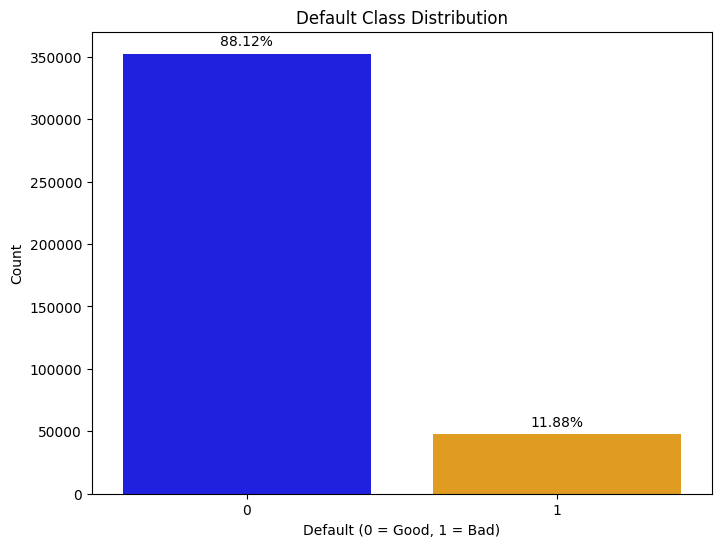

In [33]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
custom_colors = {0: "blue", 1: "orange"}
ax = sns.countplot(data=loan, x='target', hue='target', palette=custom_colors, legend=False)


plt.title("Default Class Distribution")
plt.xlabel("Default (0 = Good, 1 = Bad)")
plt.ylabel("Count")


total = len(loan)

for p in ax.patches:
    count = p.get_height()
    percentage = f'{100 * count / total:.2f}%'
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()
    ax.text(x, y + total * 0.01, percentage, ha='center', va='bottom')

plt.show()


In [34]:
corr_pos = loan.corr(numeric_only=True)['target'].sort_values(ascending=False)
selected_feature1 = corr_pos.index[:15]
corr_pos.head(30)


,target
target,1.000000
recoveries,0.527865
collection_recovery_fee,0.500351
int_rate,0.196810
hardship_dpd,0.139277
sec_app_inq_last_6mths,0.099595
total_rec_late_fee,0.094880
acc_open_past_24mths,0.091665
inq_last_6mths,0.082802
num_tl_op_past_12m,0.080781


In [35]:
selected_feature1

Index(['target', 'recoveries', 'collection_recovery_fee', 'int_rate',
       'hardship_dpd', 'sec_app_inq_last_6mths', 'total_rec_late_fee',
       'acc_open_past_24mths', 'inq_last_6mths', 'num_tl_op_past_12m',
       'open_rv_24m', 'percent_bc_gt_75', 'bc_util', 'inq_last_12m',
       'revol_util'],
      dtype='object')

In [36]:
# Numeric_only=True here as well
corr_neg = loan.corr(numeric_only=True)['target'].sort_values(ascending=True)
selected_feature2 = corr_neg.index[:15]
print(corr_neg.head(30))

last_fico_range_high                  -0.600920
last_fico_range_low                   -0.557002
total_rec_prncp                       -0.225445
out_prncp                             -0.210470
out_prncp_inv                         -0.210448
last_pymnt_amnt                       -0.180610
total_pymnt                           -0.140313
total_pymnt_inv                       -0.140197
fico_range_low                        -0.119775
fico_range_high                       -0.119773
sec_app_fico_range_low                -0.106761
sec_app_fico_range_high               -0.106761
bc_open_to_buy                        -0.081308
settlement_percentage                 -0.076661
total_bc_limit                        -0.072566
sec_app_mths_since_last_major_derog   -0.064402
tot_hi_cred_lim                       -0.063014
mths_since_recent_inq                 -0.059829
annual_inc_joint                      -0.059587
total_rev_hi_lim                      -0.058225
avg_cur_bal                           -0

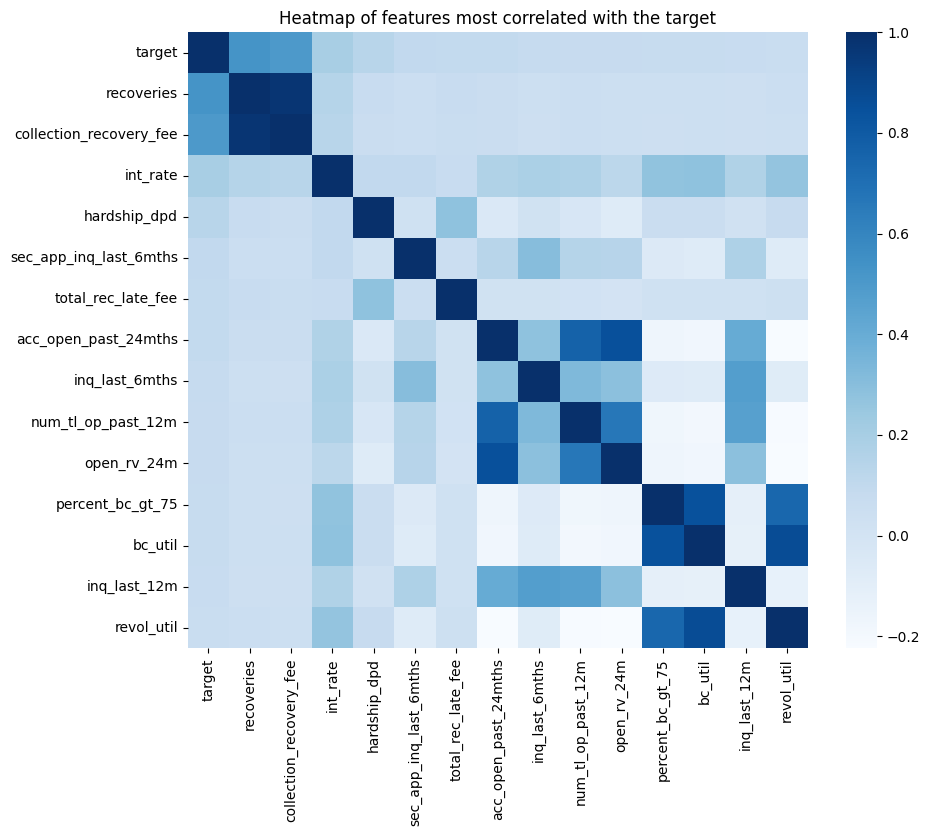

In [37]:
plt.figure(figsize=(10, 8))
# Filter the correlation matrix to only look at the selected features
sns.heatmap(loan[selected_feature1].corr(), cmap="Blues")
plt.title("Heatmap of features most correlated with the target")

None

In [38]:
missing_percent = loan.isnull().mean() * 100
missing_percent_sorted = missing_percent.sort_values(ascending=False)
missing_percent_sorted

,0
member_id,100.00000
orig_projected_additional_accrued_interest,99.61775
payment_plan_start_date,99.50650
hardship_status,99.50650
hardship_start_date,99.50650
...,...
hardship_flag,0.00100
disbursement_method,0.00100
id,0.00000
target,0.00000


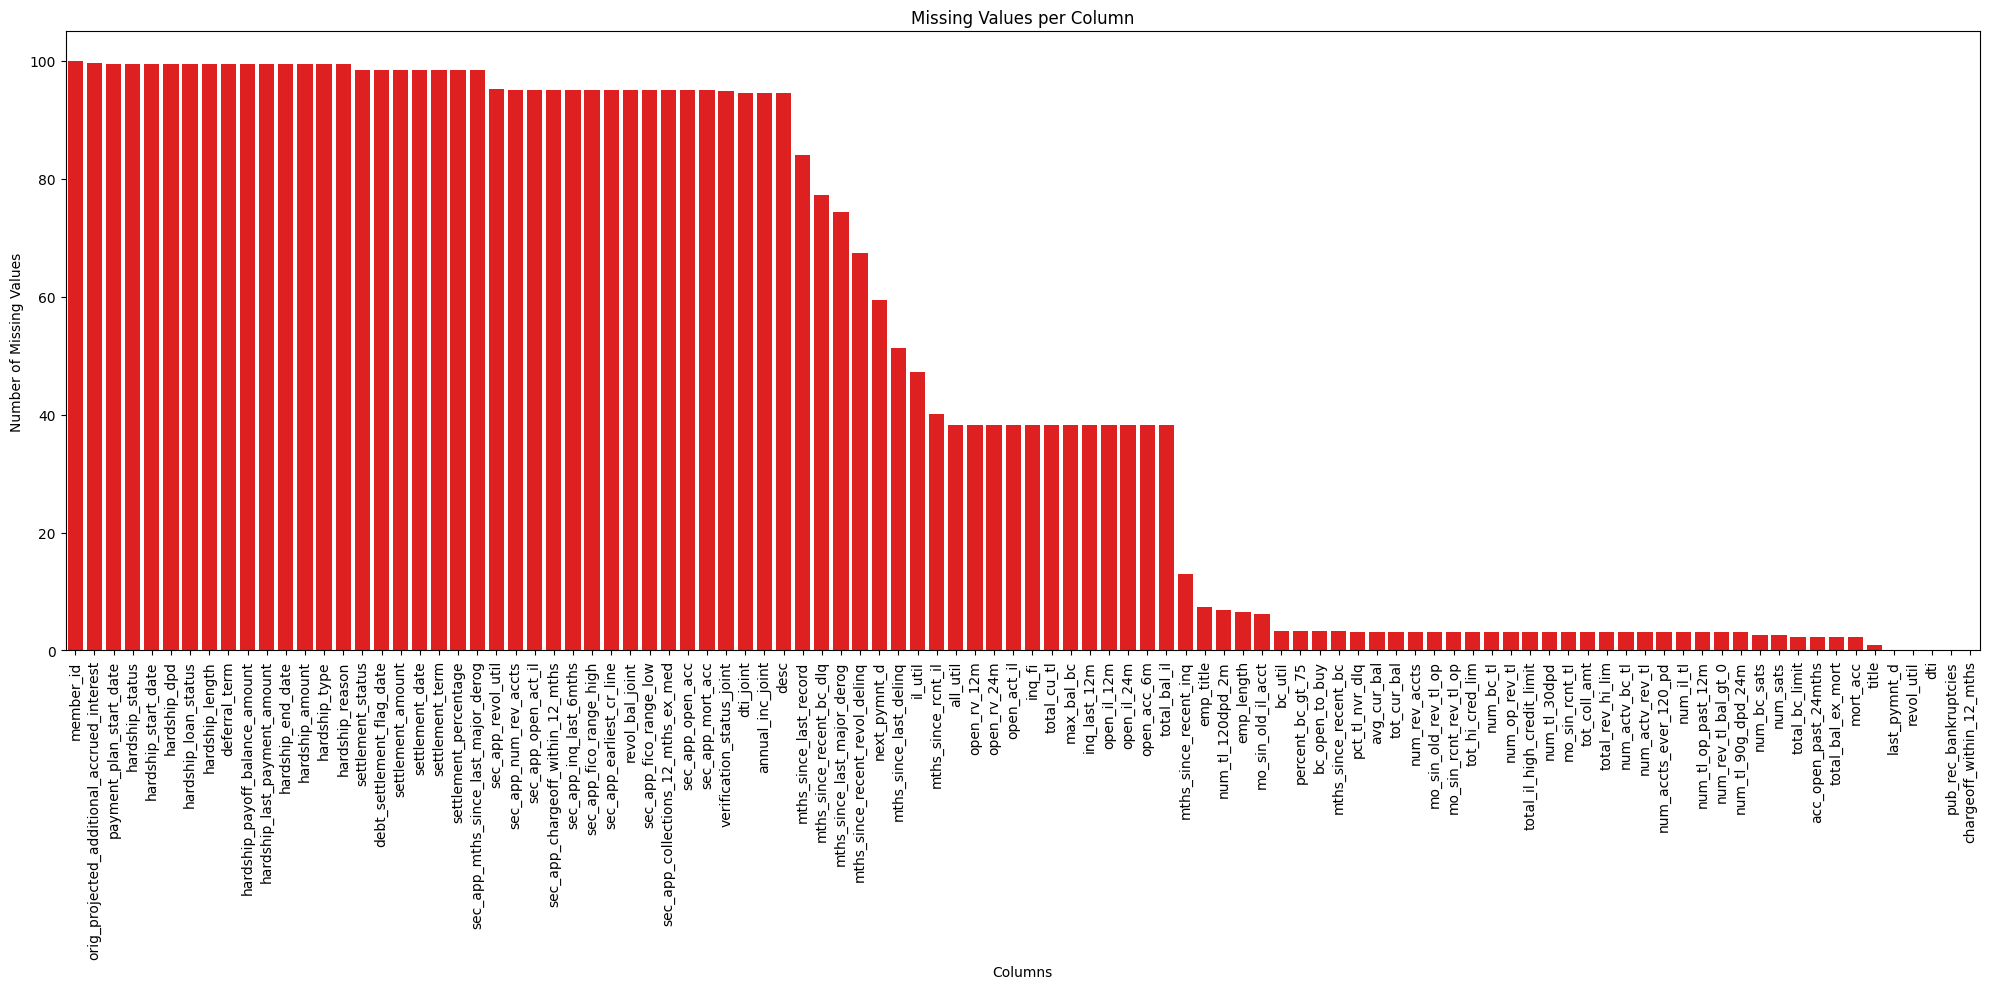

In [39]:
plt.figure(figsize=(20, 10))
sns.barplot(x=missing_percent_sorted.index[:100], y=missing_percent_sorted.values[:100], color="red")
plt.title("Missing Values per Column")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [40]:
unique = pd.DataFrame(loan.nunique(), columns=["Count"])
unique["Count"].sort_values(ascending=False)

,Count
id,400000
url,399996
total_pymnt,344290
total_pymnt_inv,325282
total_rec_int,253061
...,...
policy_code,1
hardship_type,1
deferral_term,1
hardship_length,1


In [41]:
nominal_columns = loan.select_dtypes(exclude=['number'])
nominal_columns

,id,term,grade,sub_grade,emp_title,emp_length,home_ownership,verification_status,issue_d,loan_status,...,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_loan_status,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,dataset_type
0,1006259,36 months,B,B3,NaN,2 years,OWN,Source Verified,Nov-2011,Fully Paid,...,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,train
1,50303671,36 months,E,E2,New Patient Check in,1 year,MORTGAGE,Source Verified,Jun-2015,Fully Paid,...,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,train
2,30485774,36 months,B,B4,RN,10+ years,MORTGAGE,Source Verified,Oct-2014,Fully Paid,...,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,train
3,29183992,36 months,E,E1,Assistant customer service manager,1 year,RENT,Not Verified,Oct-2014,Fully Paid,...,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,train
4,62644235,36 months,A,A5,Officer,< 1 year,OWN,Not Verified,Oct-2015,Fully Paid,...,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,train
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
399995,560678,36 months,C,C3,Associate Professor,4 years,MORTGAGE,Source Verified,Mar-2016,Fully Paid,...,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,test
399996,1625136,36 months,A,A5,WCND,10+ years,MORTGAGE,Not Verified,Oct-2012,Fully Paid,...,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,test
399997,136551975,60 months,C,C3,Assistant Pricipal,3 years,MORTGAGE,Verified,Jul-2018,Current,...,NaN,NaN,NaN,NaN,DirectPay,N,NaN,NaN,NaN,test
399998,122303361,36 months,B,B5,Office Assistant 2,10+ years,RENT,Source Verified,Nov-2017,Current,...,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,test


#### Now I will try to identify categorical features, both nominal categorical and ordinal categorical

In [42]:
nominal_columns = loan.select_dtypes(exclude=['number'])
nominal_columns

,id,term,grade,sub_grade,emp_title,emp_length,home_ownership,verification_status,issue_d,loan_status,...,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_loan_status,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,dataset_type
0,1006259,36 months,B,B3,NaN,2 years,OWN,Source Verified,Nov-2011,Fully Paid,...,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,train
1,50303671,36 months,E,E2,New Patient Check in,1 year,MORTGAGE,Source Verified,Jun-2015,Fully Paid,...,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,train
2,30485774,36 months,B,B4,RN,10+ years,MORTGAGE,Source Verified,Oct-2014,Fully Paid,...,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,train
3,29183992,36 months,E,E1,Assistant customer service manager,1 year,RENT,Not Verified,Oct-2014,Fully Paid,...,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,train
4,62644235,36 months,A,A5,Officer,< 1 year,OWN,Not Verified,Oct-2015,Fully Paid,...,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,train
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
399995,560678,36 months,C,C3,Associate Professor,4 years,MORTGAGE,Source Verified,Mar-2016,Fully Paid,...,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,test
399996,1625136,36 months,A,A5,WCND,10+ years,MORTGAGE,Not Verified,Oct-2012,Fully Paid,...,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,test
399997,136551975,60 months,C,C3,Assistant Pricipal,3 years,MORTGAGE,Verified,Jul-2018,Current,...,NaN,NaN,NaN,NaN,DirectPay,N,NaN,NaN,NaN,test
399998,122303361,36 months,B,B5,Office Assistant 2,10+ years,RENT,Source Verified,Nov-2017,Current,...,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,test


In [43]:
null_nominal = (nominal_columns.isnull().mean() * 100).sort_values(ascending=False)
null_nominal

,0
hardship_type,99.50650
hardship_status,99.50650
hardship_start_date,99.50650
hardship_end_date,99.50650
payment_plan_start_date,99.50650
hardship_loan_status,99.50650
hardship_reason,99.50650
debt_settlement_flag_date,98.48825
settlement_date,98.48825
settlement_status,98.48825


In [44]:
# Trying to identify other categorical features, i.e ordinal categorical ones
# by examining columns with relatively few unique values.
unique.sort_values(by="Count", ascending=False)[:20]

,Count
id,400000
url,399996
total_pymnt,344290
total_pymnt_inv,325282
total_rec_int,253061
tot_hi_cred_lim,225920
tot_cur_bal,220233
last_pymnt_amnt,188004
total_rec_prncp,135645
emp_title,129418


In [45]:
# Features with 2 to 20 unique numerical values (excluding NaNs) might be categorical,
# possibly ordinal categorical if the values represent a meaningful order.

cols_unique_20 = unique[(unique['Count'] <= 20) & (unique['Count'] > 1)].index
print("These features are considered ordinal categorical")
cols_unique_20

These features are considered ordinal categorical


Index(['term', 'grade', 'emp_length', 'home_ownership', 'verification_status',
       'loan_status', 'pymnt_plan', 'purpose', 'inq_last_6mths',
       'initial_list_status', 'collections_12_mths_ex_med', 'application_type',
       'verification_status_joint', 'acc_now_delinq', 'open_acc_6m',
       'open_il_12m', 'chargeoff_within_12_mths', 'num_tl_120dpd_2m',
       'num_tl_30dpd', 'pub_rec_bankruptcies', 'sec_app_inq_last_6mths',
       'sec_app_mort_acc', 'sec_app_chargeoff_within_12_mths',
       'sec_app_collections_12_mths_ex_med', 'hardship_flag',
       'hardship_reason', 'hardship_status', 'hardship_loan_status',
       'disbursement_method', 'debt_settlement_flag', 'settlement_status',
       'target', 'dataset_type'],
      dtype='object')

In [46]:
# Checking the percentage of missing values in potential ordinal categorical features

missing_percent_unique_20 = pd.DataFrame(loan[cols_unique_20].isnull().mean()* 100, columns=["Percent_Null"])

print("Possible ordinal categorical features with 60% or fewer missing values:")
missing_percent_unique_20[missing_percent_unique_20['Percent_Null'] <= 60]

Possible ordinal categorical features with 60% or fewer missing values:


,Percent_Null
term,0.00100
grade,0.00100
emp_length,6.51150
home_ownership,0.00100
verification_status,0.00100
loan_status,0.00100
pymnt_plan,0.00100
purpose,0.00100
inq_last_6mths,0.00225
initial_list_status,0.00100


In [47]:
# Trying to identify features with a lot of "categories" which might be difficult to interpret
# and might need to dropped.
cols_unique_50 = unique[(unique['Count'] > 20) & (unique['Count'] < 4000)].index
print("These features are considered ordinal categorical")
cols_unique_50

These features are considered ordinal categorical


Index(['loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'int_rate', 'sub_grade',
       'issue_d', 'zip_code', 'addr_state', 'delinq_2yrs', 'earliest_cr_line',
       'fico_range_low', 'fico_range_high', 'mths_since_last_delinq',
       'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_util',
       'total_acc', 'last_pymnt_d', 'next_pymnt_d', 'last_credit_pull_d',
       'last_fico_range_high', 'last_fico_range_low',
       'mths_since_last_major_derog', 'dti_joint', 'open_act_il',
       'open_il_24m', 'mths_since_rcnt_il', 'il_util', 'open_rv_12m',
       'open_rv_24m', 'all_util', 'inq_fi', 'total_cu_tl', 'inq_last_12m',
       'acc_open_past_24mths', 'bc_util', 'delinq_amnt', 'mo_sin_old_il_acct',
       'mo_sin_old_rev_tl_op', 'mo_sin_rcnt_rev_tl_op', 'mo_sin_rcnt_tl',
       'mort_acc', 'mths_since_recent_bc', 'mths_since_recent_bc_dlq',
       'mths_since_recent_inq', 'mths_since_recent_revol_delinq',
       'num_accts_ever_120_pd', 'num_actv_bc_tl', 'num_actv_rev_tl',
    

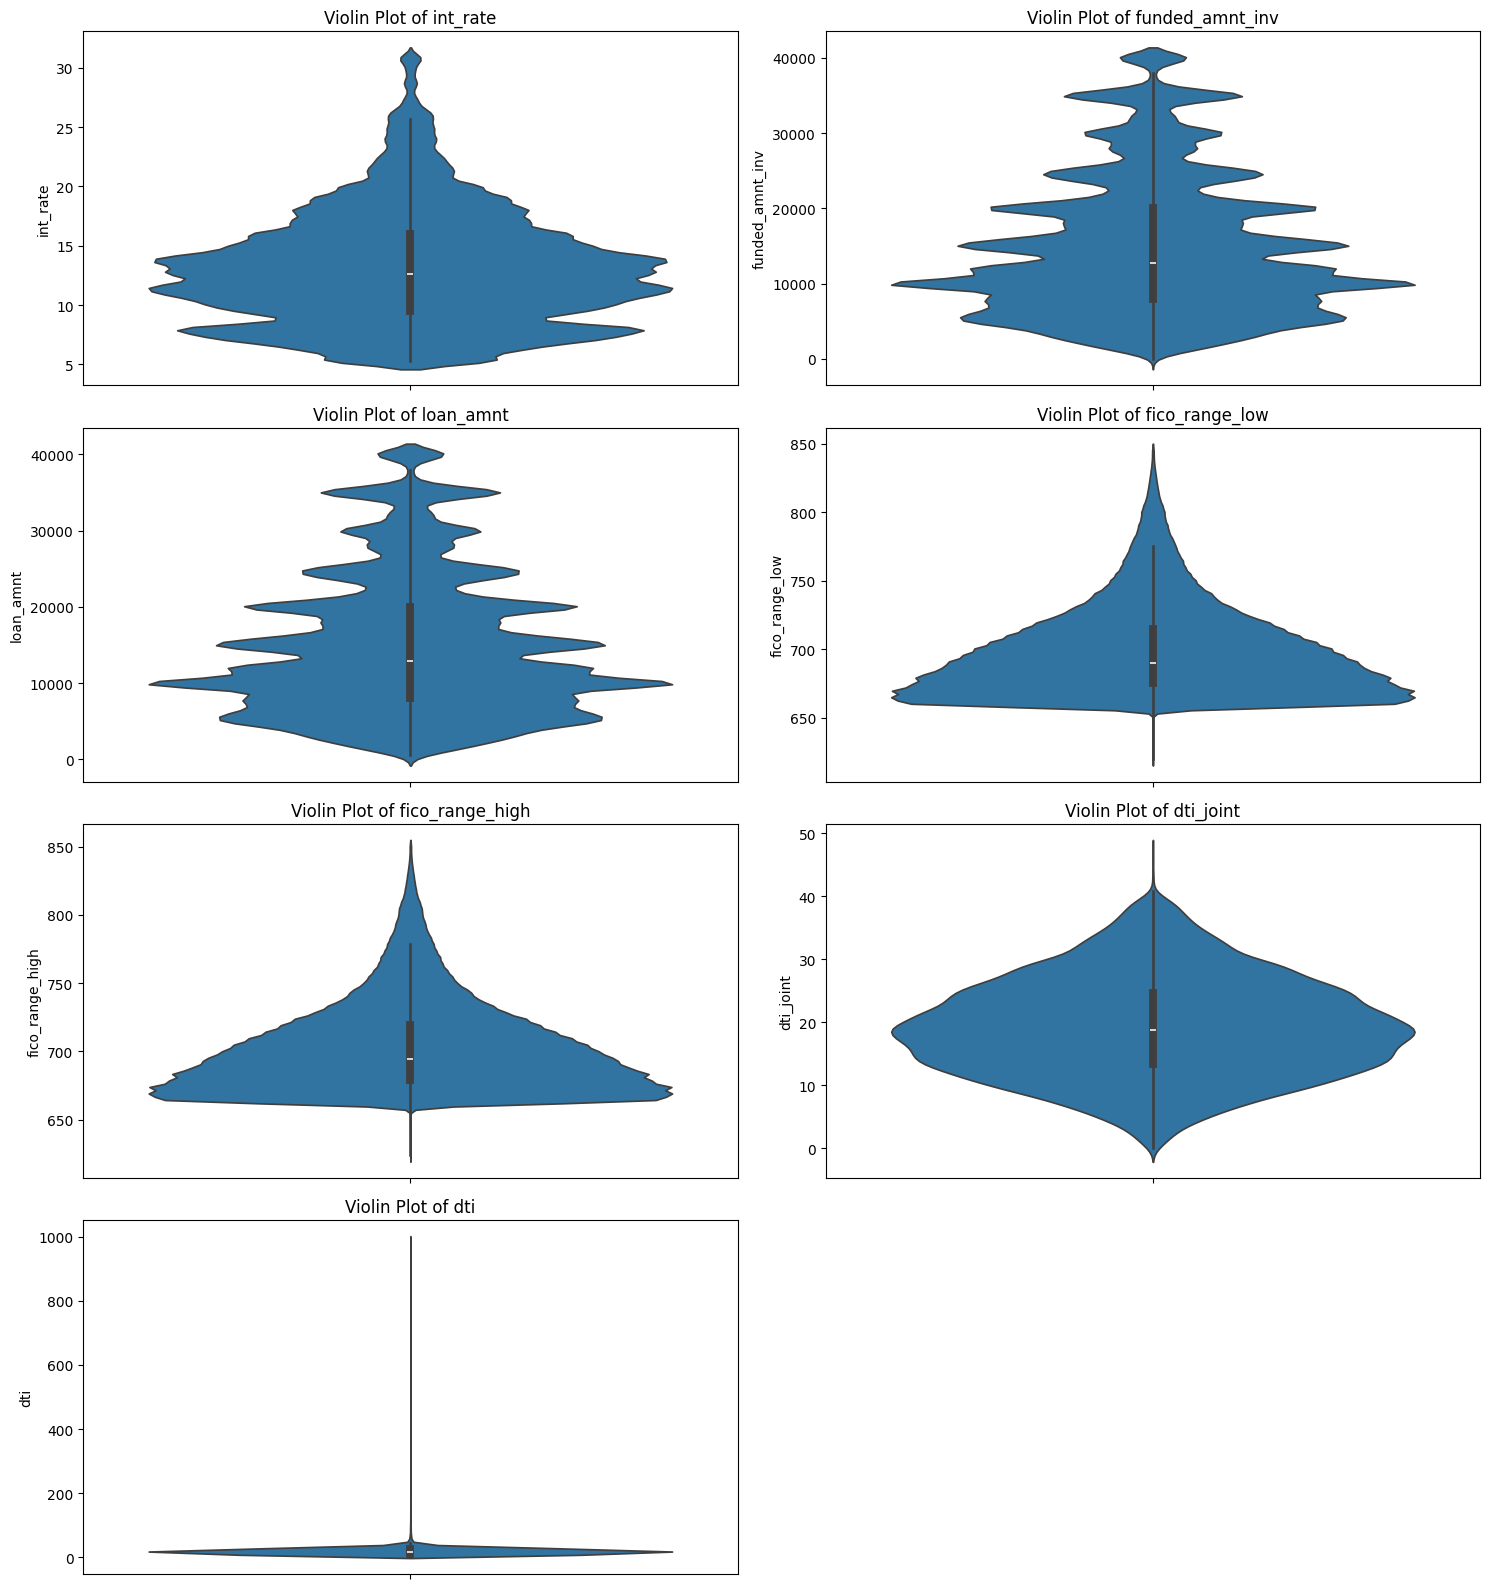

In [48]:
features = ['int_rate','funded_amnt_inv','loan_amnt', 'fico_range_low', 'fico_range_high', 'dti_joint', 'dti']
num_features = len(features)
cols = 2
rows = (num_features + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(15, 4 * rows))
axes = axes.flatten()

for i, feature in enumerate(features):

    if loan[feature].dtype.kind in 'biufc':
        sns.violinplot(y=loan[feature], ax=axes[i])
        axes[i].set_title(f'Violin Plot of {feature}')
        axes[i].set_xlabel('')
        axes[i].set_ylabel(feature)
        axes[i].grid(False)
    else:
        axes[i].axis('off')
        axes[i].set_title(f'Skipped: {feature} (non-numeric)', fontsize=10)


for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

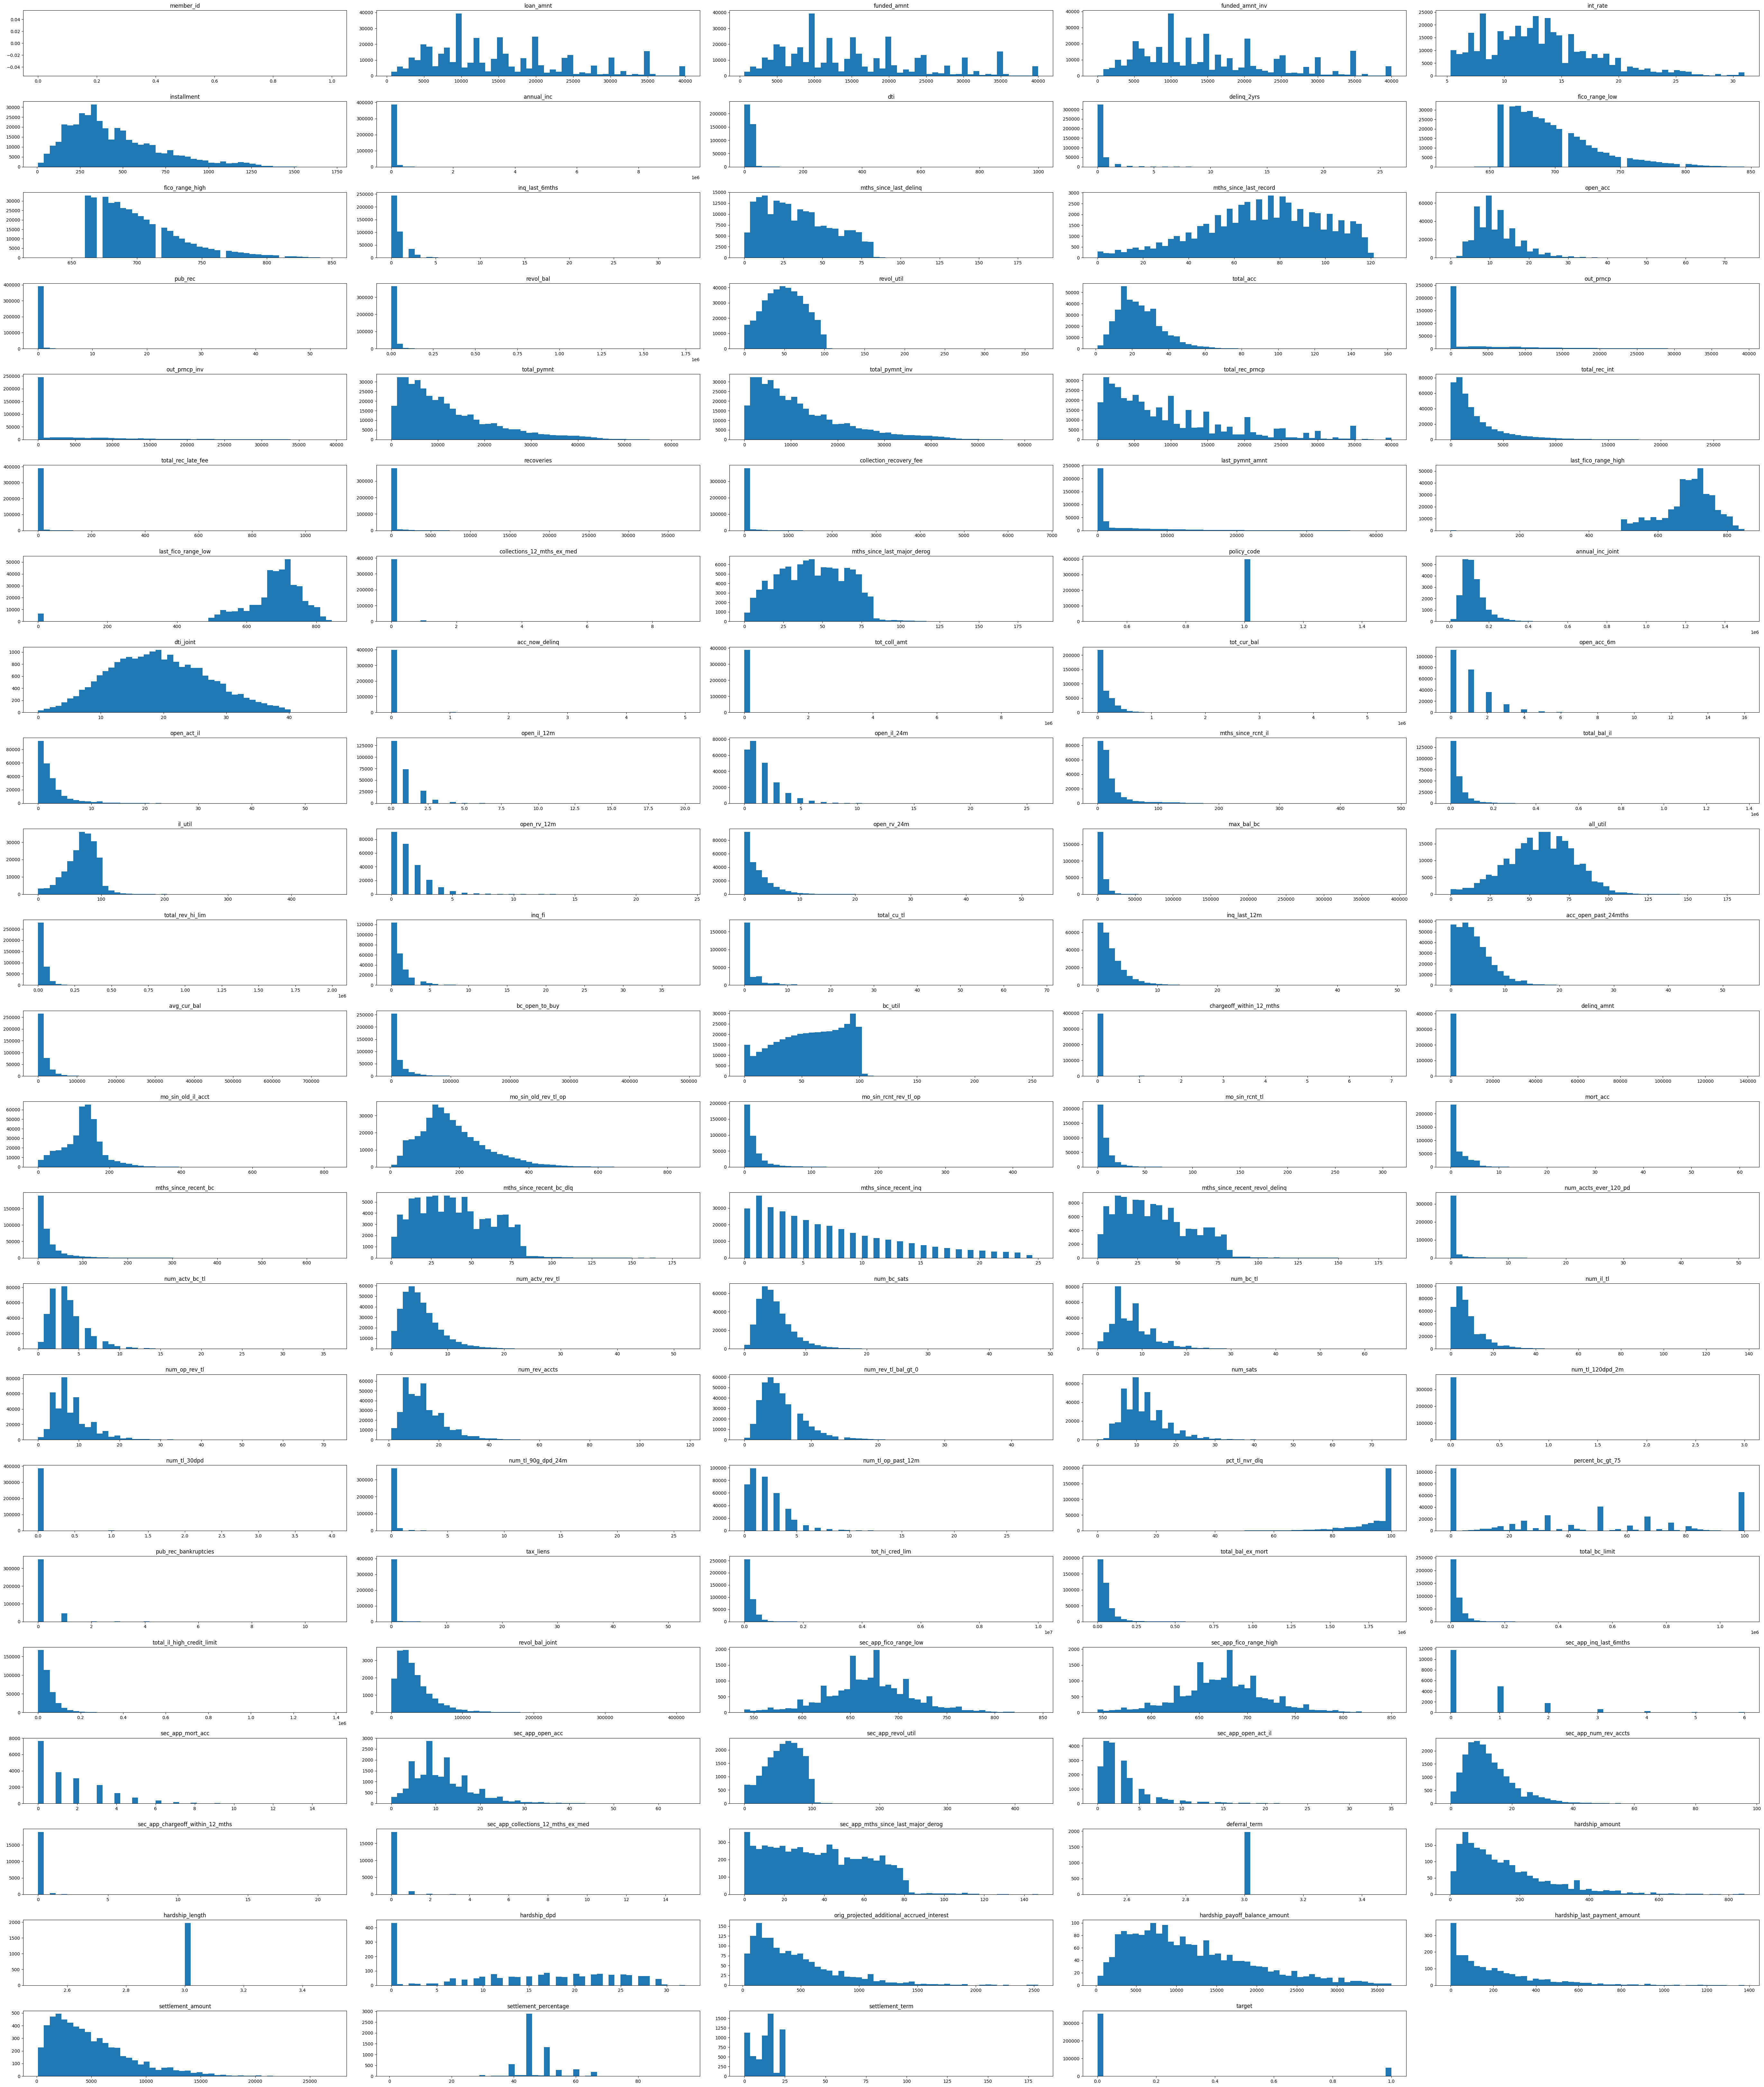

In [49]:
import matplotlib.pyplot as plt

m = 5
loan.hist(figsize=(55, 65), layout=(-1, m), bins=50, grid=False)
plt.tight_layout()
plt.show()

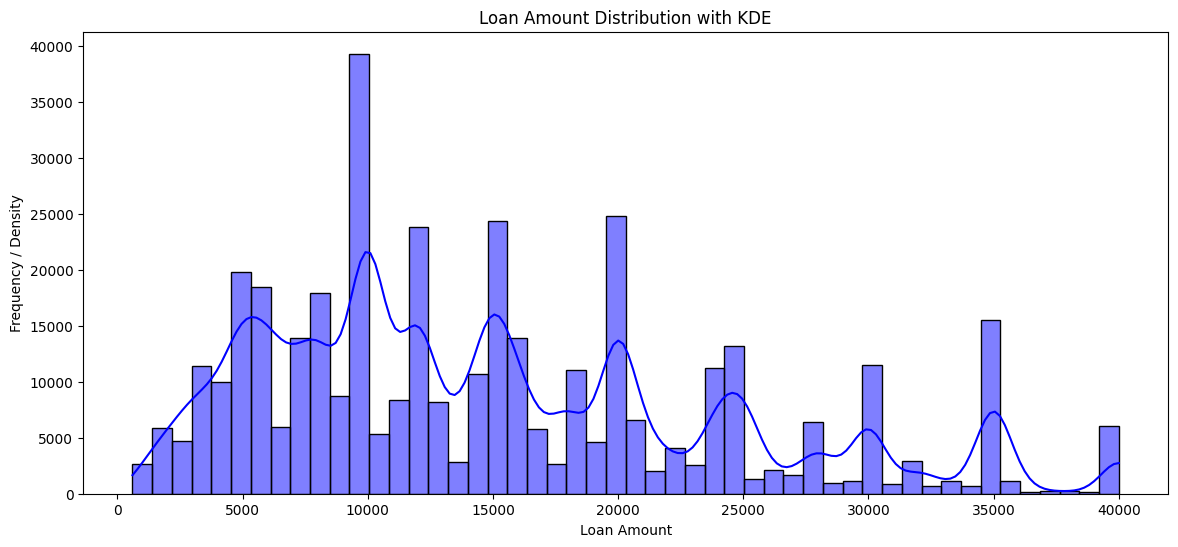

In [50]:
plt.figure(figsize = (14,6))
sns.histplot(x = "loan_amnt", data=loan, color = 'blue', bins = 50, kde=True)
plt.title("Loan Amount Distribution with KDE")
plt.xlabel("Loan Amount")
plt.ylabel("Frequency / Density")
plt.show()

/tmp/ipykernel_925/381261010.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  graph.set_xticklabels(graph.get_xticklabels(),rotation=90)


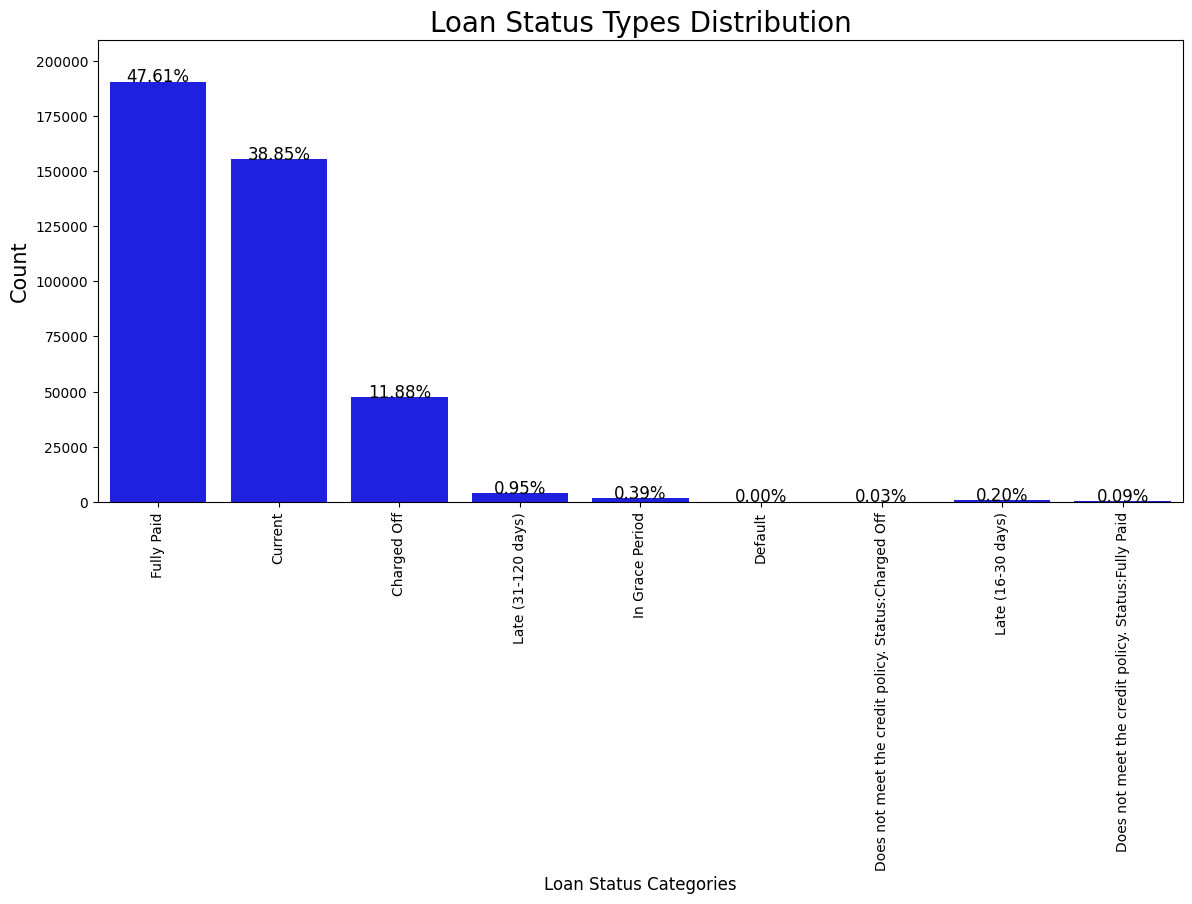

In [51]:
total = len(loan)

plt.figure(figsize = (14,6))

graph = sns.countplot(x="loan_status", data=loan,
                  color='blue')
graph.set_xticklabels(graph.get_xticklabels(),rotation=90)
graph.set_xlabel("Loan Status Categories", fontsize=12)
graph.set_ylabel("Count", fontsize=15)
graph.set_title("Loan Status Types Distribution", fontsize=20)
sizes=[]
for p in graph.patches:
    height = p.get_height()
    sizes.append(height)
    graph.text(p.get_x()+p.get_width()/2.,
            height + 3,
            '{:1.2f}%'.format(height/total*100),
            ha="center", fontsize=12)
graph.set_ylim(0, max(sizes) * 1.10)

plt.show()

/tmp/ipykernel_925/3385035518.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  g.set_xticklabels(g.get_xticklabels(),


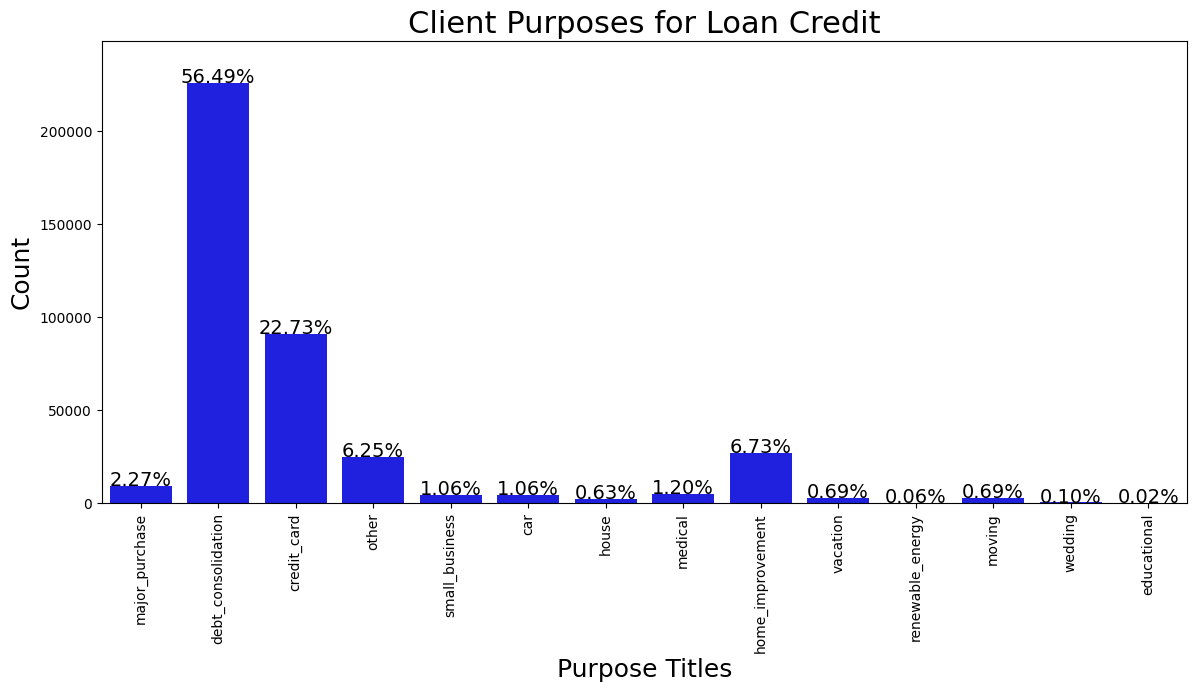

In [52]:
plt.figure(figsize=(14,6))

g = sns.countplot(x='purpose', data=loan,
                  color='blue')
g.set_title("Client Purposes for Loan Credit", fontsize=22)
g.set_xlabel("Purpose Titles", fontsize=18)
g.set_ylabel('Count', fontsize=18)

sizes=[]

for p in g.patches:
    height = p.get_height()
    sizes.append(height)
    g.text(p.get_x()+p.get_width()/2.,
            height + 3,
            '{:1.2f}%'.format(height/total*100),
            ha="center", fontsize=14)

g.set_ylim(0, max(sizes) * 1.10)
g.set_xticklabels(g.get_xticklabels(),
                  rotation=90)

plt.show()

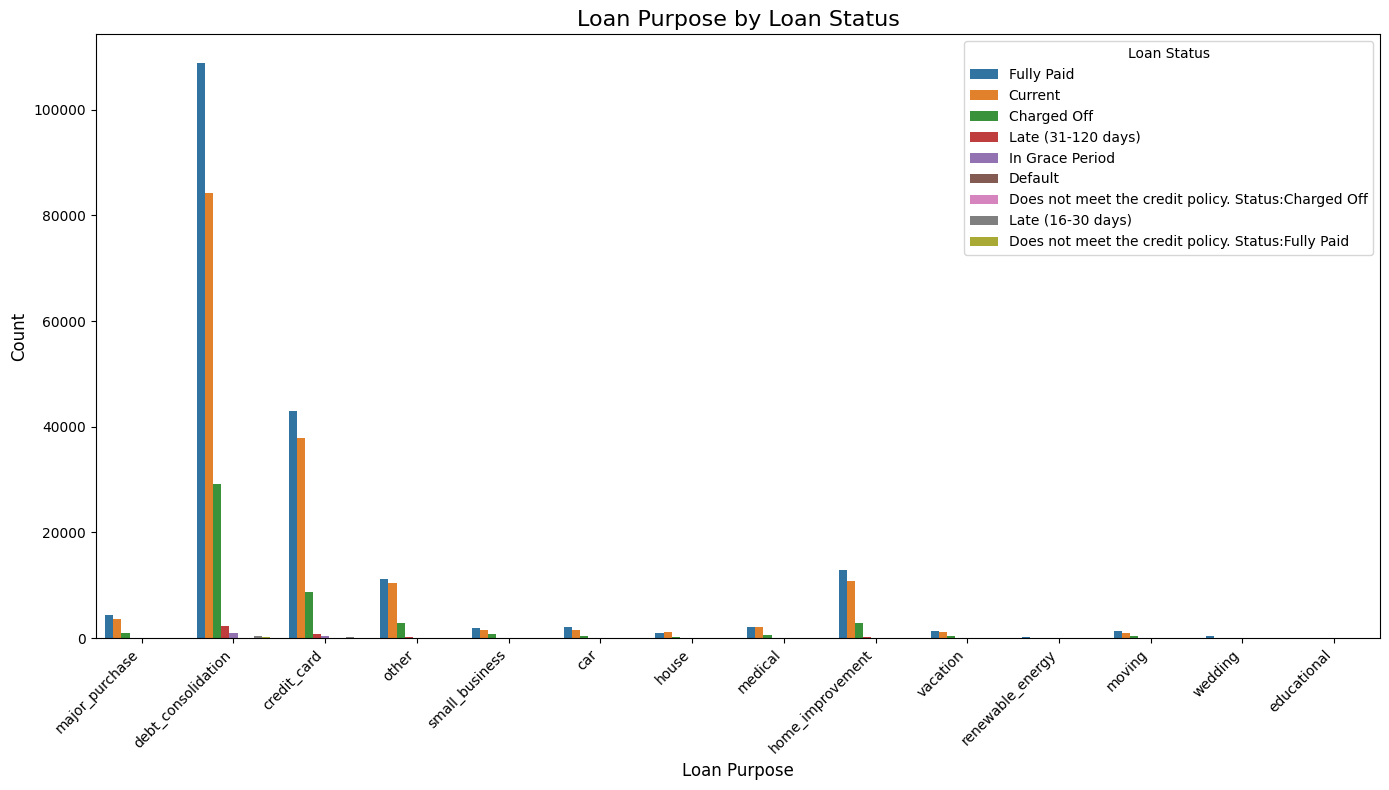

In [53]:

plt.figure(figsize=(14, 8))
sns.countplot(data=loan, x='purpose', hue='loan_status')

plt.xticks(rotation=45, ha='right')
plt.xlabel('Loan Purpose', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.title('Loan Purpose by Loan Status', fontsize=16)
plt.legend(title='Loan Status')
plt.tight_layout()
plt.show()


In [54]:
# Looking more closely at the following features
features = ['loan_amnt', 'term','int_rate', 'sub_grade', 'emp_length', 'home_ownership', 'annual_inc', 'loan_status', 'addr_state', 'dti', 'mths_since_recent_inq', 'revol_util', 'bc_open_to_buy', 'bc_util', 'num_op_rev_tl']

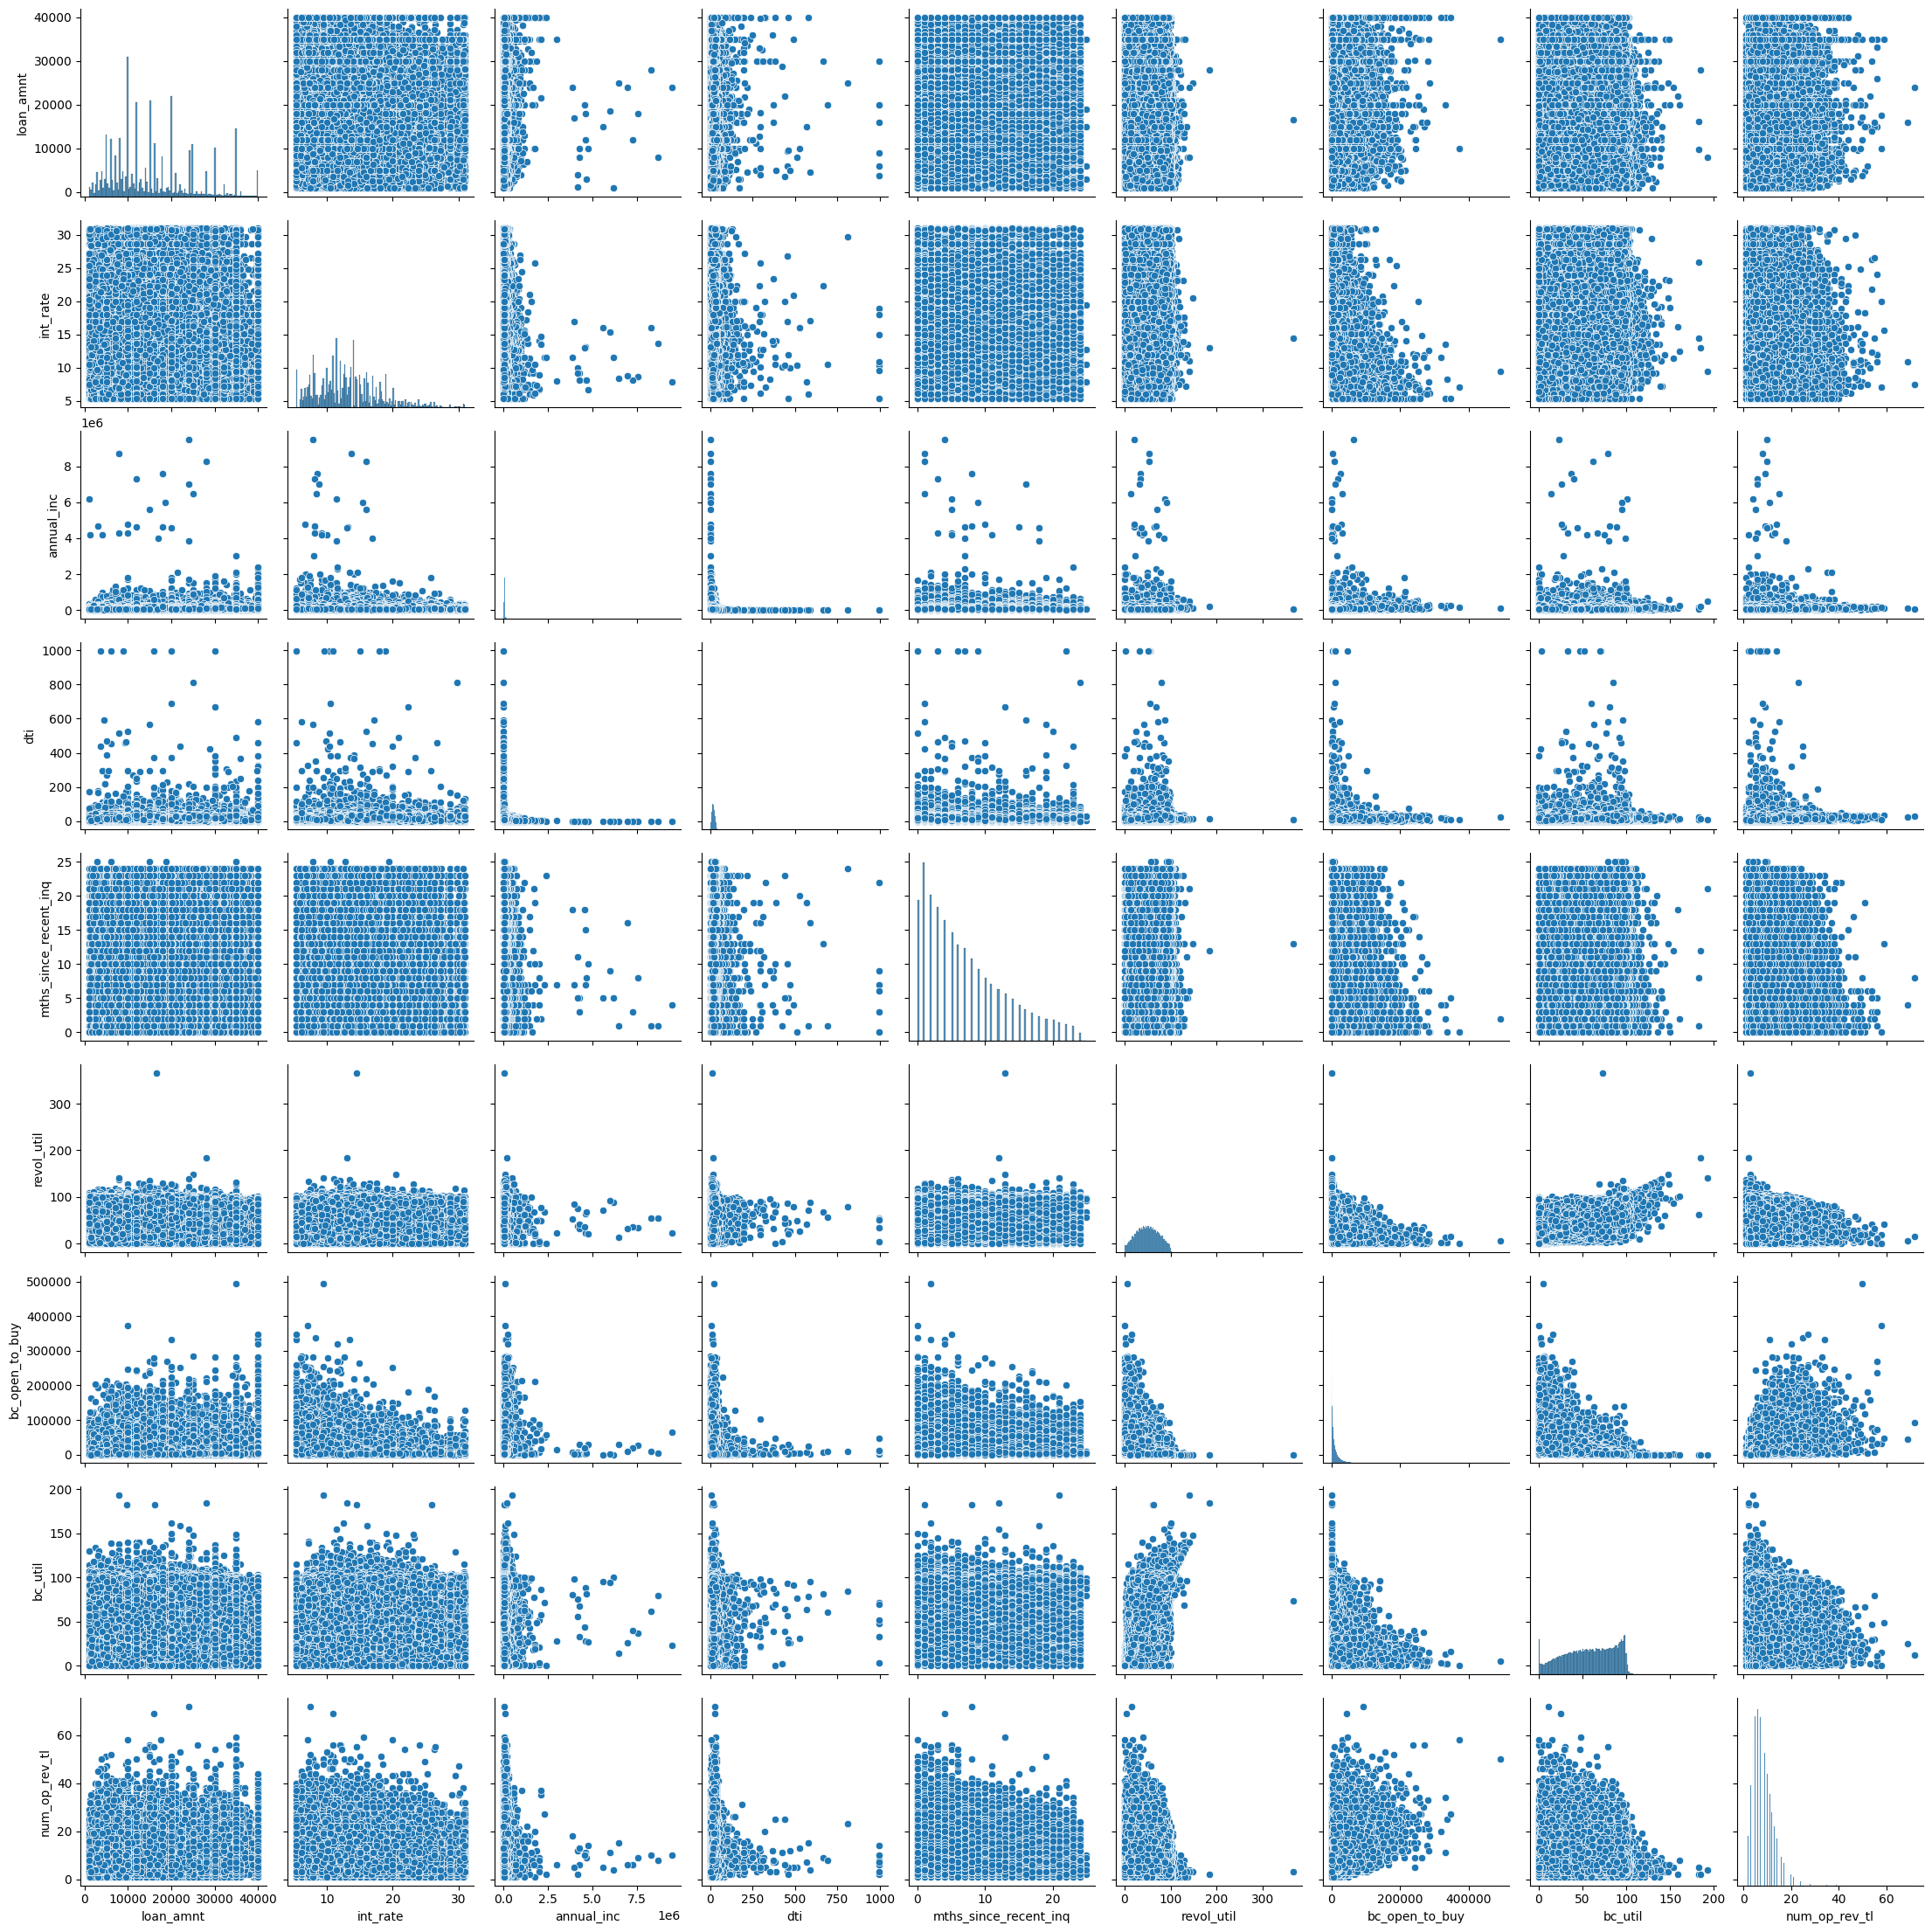

In [55]:
selected_features = loan[features]
selected_features = selected_features.dropna()

sns.pairplot(data=selected_features)
plt.grid(False)
plt.show()

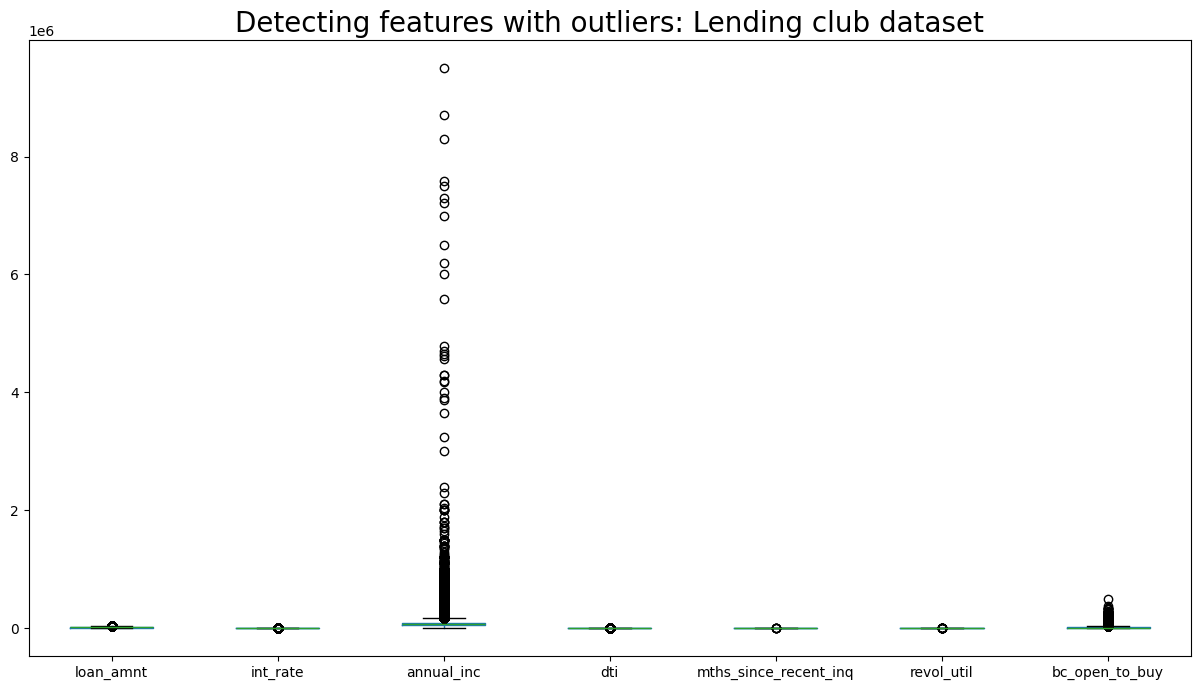

In [56]:
num_cols = ['loan_amnt','int_rate', 'sub_grade', 'emp_length', 'annual_inc', 'dti','mths_since_recent_inq', 'revol_util', 'bc_open_to_buy']


plt.figure(figsize=(15,8))
loan[num_cols].boxplot()
plt.title("Detecting features with outliers: Lending club dataset", fontsize=20)
plt.grid(False)
plt.show()

#### Looking for outliers using the Loan Amount Column.
##### Looking for very "high" values first.

In [57]:
num_percentile = 0.985
high_percentile = loan['loan_amnt'].quantile(num_percentile)
outliers_high_value = loan[(loan['loan_amnt'] > high_percentile)]
print(f"Outliers count above the {num_percentile*100:.2f}th centile: {outliers_high_value['loan_amnt'].count()}")
outliers_high_value.sort_values(by='loan_amnt', ascending=False)

Outliers count above the 98.50th centile: 5987


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term,target,dataset_type
399967,141275862,NaN,40000.0,40000.0,40000.0,36 months,7.21,1238.93,A,A3,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,test
111,128693358,NaN,40000.0,40000.0,40000.0,36 months,6.72,1229.97,A,A3,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,train
164,78011783,NaN,40000.0,40000.0,40000.0,60 months,8.39,818.55,B,B1,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,train
397500,88645485,NaN,40000.0,40000.0,40000.0,36 months,5.32,1204.60,A,A1,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,test
397514,81100805,NaN,40000.0,40000.0,40000.0,36 months,15.31,1392.70,C,C5,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,1,test
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
313821,134143831,NaN,39700.0,39700.0,39700.0,36 months,10.07,1282.32,B,B2,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,test
138089,137895188,NaN,39700.0,39700.0,39700.0,36 months,10.08,1282.50,B,B1,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,train
145672,140605943,NaN,39700.0,39700.0,39700.0,36 months,11.55,1310.10,B,B4,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,train
375734,142977126,NaN,39650.0,39650.0,39650.0,60 months,10.08,844.01,B,B1,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,test


### Now dropping high loan amounts

In [58]:
loan = loan.drop(loan[loan['loan_amnt'] > high_percentile].index)
loan['loan_amnt'].sort_values(ascending = False)

,loan_amnt
27936,39600.0
333573,39600.0
308503,39600.0
342022,39600.0
393994,39600.0
...,...
21868,600.0
60429,NaN
87614,NaN
217884,NaN


#### Looking for unusually low values

In [59]:
num_percentile = 0.01
low_percentile = loan['loan_amnt'].quantile(num_percentile)
outliers_low_value = loan[(loan['loan_amnt'] < low_percentile)]
print(f"Outliers count below the {num_percentile*100:.2f}th centile: {outliers_low_value['loan_amnt'].count()}")
outliers_low_value.sort_values(by='loan_amnt', ascending=False)

Outliers count below the 1.00th centile: 2974


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term,target,dataset_type
18960,113502204,NaN,1475.0,1475.0,1475.0,36 months,14.08,50.47,C,C3,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,train
83307,113097805,NaN,1475.0,1475.0,1475.0,36 months,5.32,44.42,A,A1,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,train
228818,125383698,NaN,1475.0,1475.0,1475.0,36 months,7.35,45.79,A,A4,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,test
30604,125642963,NaN,1475.0,1475.0,1475.0,36 months,9.44,47.21,B,B1,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,train
211555,10786285,NaN,1475.0,1475.0,1475.0,36 months,16.24,52.04,C,C5,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,test
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
183259,262961,NaN,900.0,900.0,875.0,36 months,8.63,28.47,A,A5,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,train
343178,150038,NaN,850.0,850.0,200.0,36 months,14.07,29.08,E,E3,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,test
316738,189524,NaN,800.0,800.0,600.0,36 months,13.43,27.13,E,E1,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,test
296796,253227,NaN,750.0,750.0,725.0,36 months,12.29,25.02,C,C5,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,test


In [60]:
loan = loan.drop(loan[loan['loan_amnt'] < low_percentile].index)
loan['loan_amnt'].sort_values(ascending = True)

,loan_amnt
93394,1500.0
243944,1500.0
33737,1500.0
33732,1500.0
238714,1500.0
...,...
296918,39600.0
60429,NaN
87614,NaN
217884,NaN


In [61]:
loan_amount = loan['loan_amnt'].dropna()
mean_amount = loan_amount.mean()
median_amount = loan_amount.median()

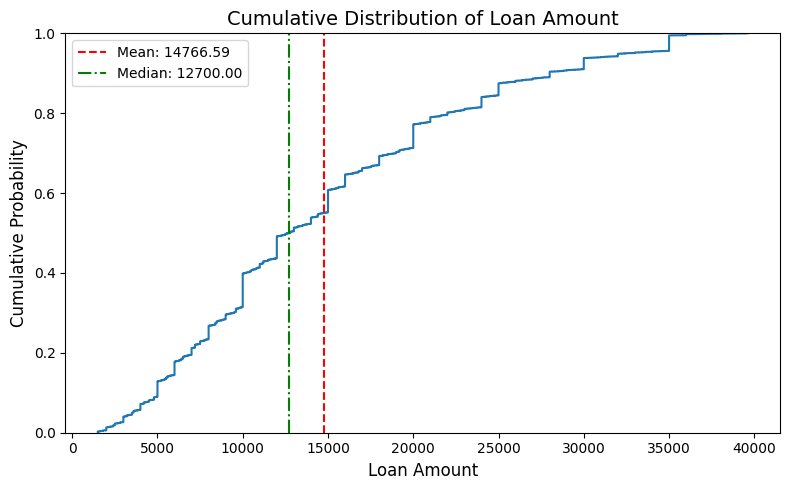

In [62]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
sns.ecdfplot(data=loan, x='loan_amnt') #,hue='target')
plt.axvline(mean_amount, color='red', linestyle='--', label=f'Mean: {mean_amount:.2f}')
plt.axvline(median_amount, color='green', linestyle='-.', label=f'Median: {median_amount:.2f}')
plt.xlabel('Loan Amount', fontsize=12)
plt.ylabel('Cumulative Probability', fontsize=12)
plt.title('Cumulative Distribution of Loan Amount', fontsize=14)
plt.legend()
plt.grid(False)
plt.tight_layout()
plt.show()


In [63]:
interest_rates = loan['int_rate'].dropna()
mean_rate = interest_rates.mean()
median_rate = interest_rates.median()

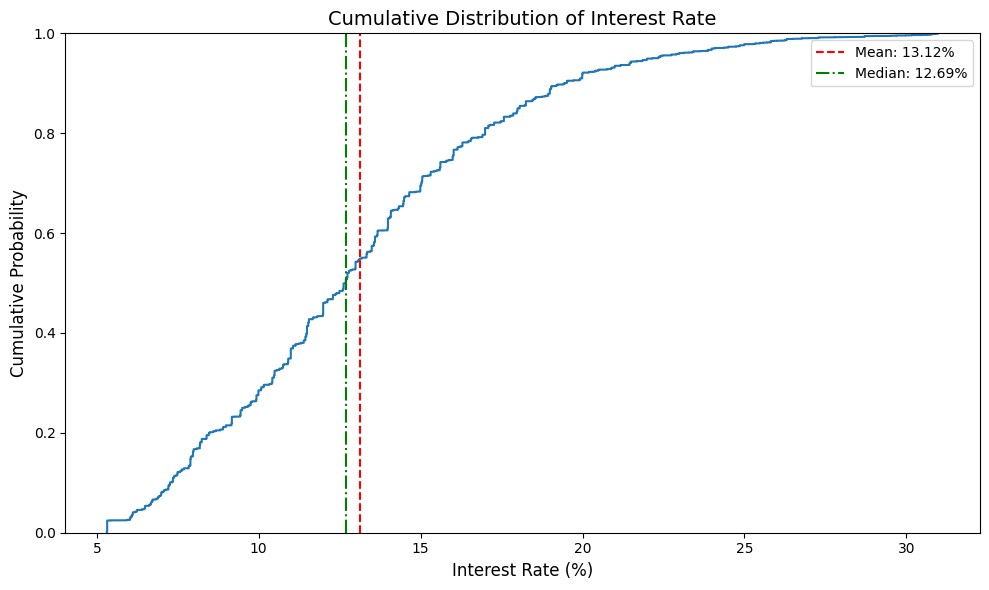

In [64]:
plt.figure(figsize=(10, 6))
sns.ecdfplot(data=interest_rates)

plt.axvline(mean_rate, color='red', linestyle='--', label=f'Mean: {mean_rate:.2f}%')
plt.axvline(median_rate, color='green', linestyle='-.', label=f'Median: {median_rate:.2f}%')

plt.xlabel('Interest Rate (%)', fontsize=12)
plt.ylabel('Cumulative Probability', fontsize=12)
plt.title('Cumulative Distribution of Interest Rate', fontsize=14)
plt.legend()
plt.grid(False)
plt.tight_layout()
plt.show()


## Addressing outliers in the Innual Income feature

In [65]:
### There are also  outliers in the annual_inc columns that I should get rid off
quarter_low = loan["annual_inc"].quantile(0.01)
quarter_high = loan["annual_inc"].quantile(0.99)
loans_extreme = loan[(loan["annual_inc"] < quarter_high) & (loan["annual_inc"] > quarter_low)]
num_cols = ['annual_inc']

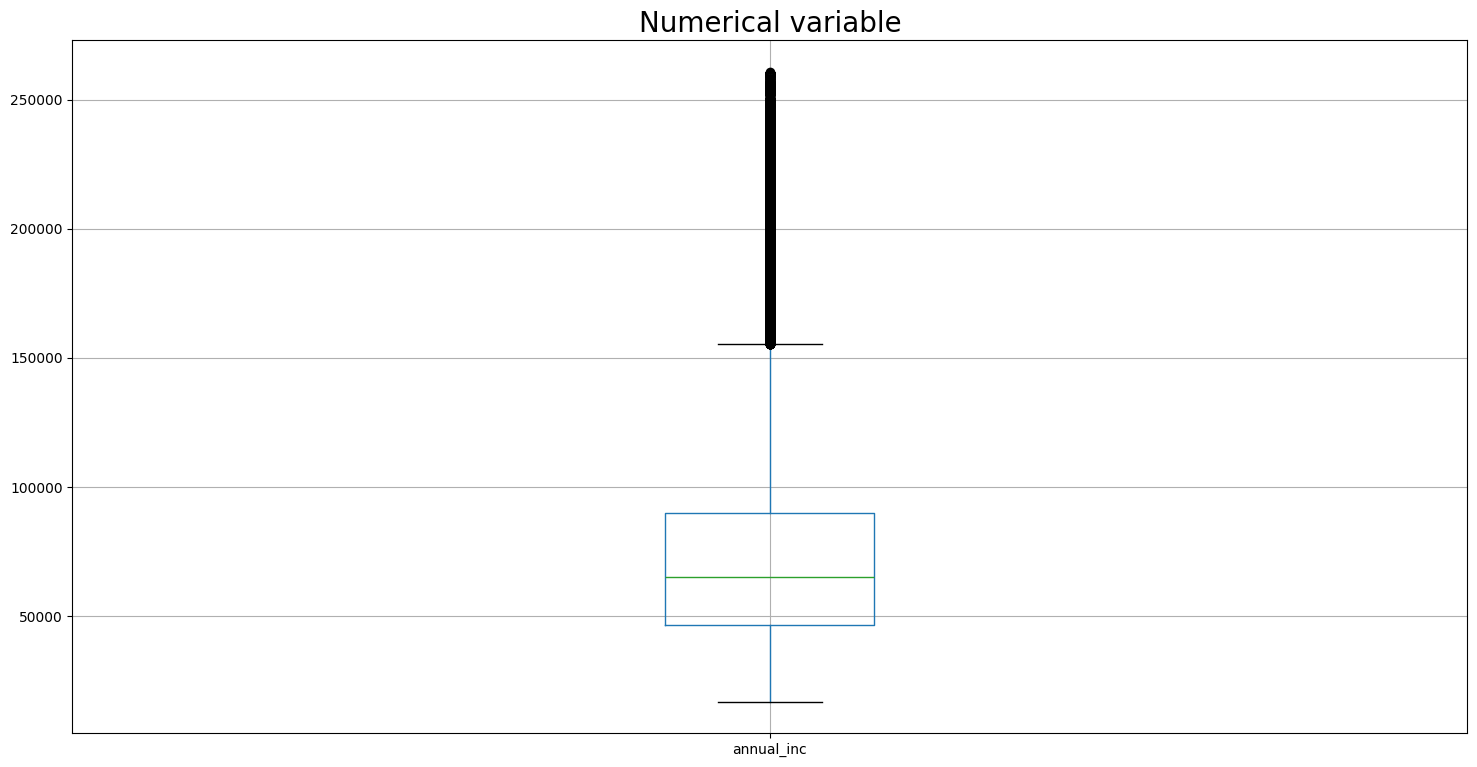

In [66]:
plt.figure(figsize=(18,9))
loans_extreme[num_cols].boxplot()
plt.title("Numerical variable", fontsize=20)
plt.show()


In [67]:
num_percentile = 0.975
high_percentile = loan['annual_inc'].quantile(num_percentile)
loan = loan[loan['annual_inc'] <= high_percentile]
loan['annual_inc'].sort_values(ascending = True)

,annual_inc
384080,0.0
113420,0.0
360552,0.0
66089,0.0
380716,0.0
...,...
56999,200000.0
254743,200000.0
363234,200000.0
317707,200000.0


In [68]:
num_percentile = 0.01
low_percentile = loan['annual_inc'].quantile(num_percentile)
loan = loan[loan['annual_inc'] >= low_percentile]
loan['annual_inc'].sort_values(ascending = False)

,annual_inc
7166,200000.00
258472,200000.00
272506,200000.00
79544,200000.00
239335,200000.00
...,...
225987,16656.00
345534,16656.00
126075,16650.00
351133,16650.00


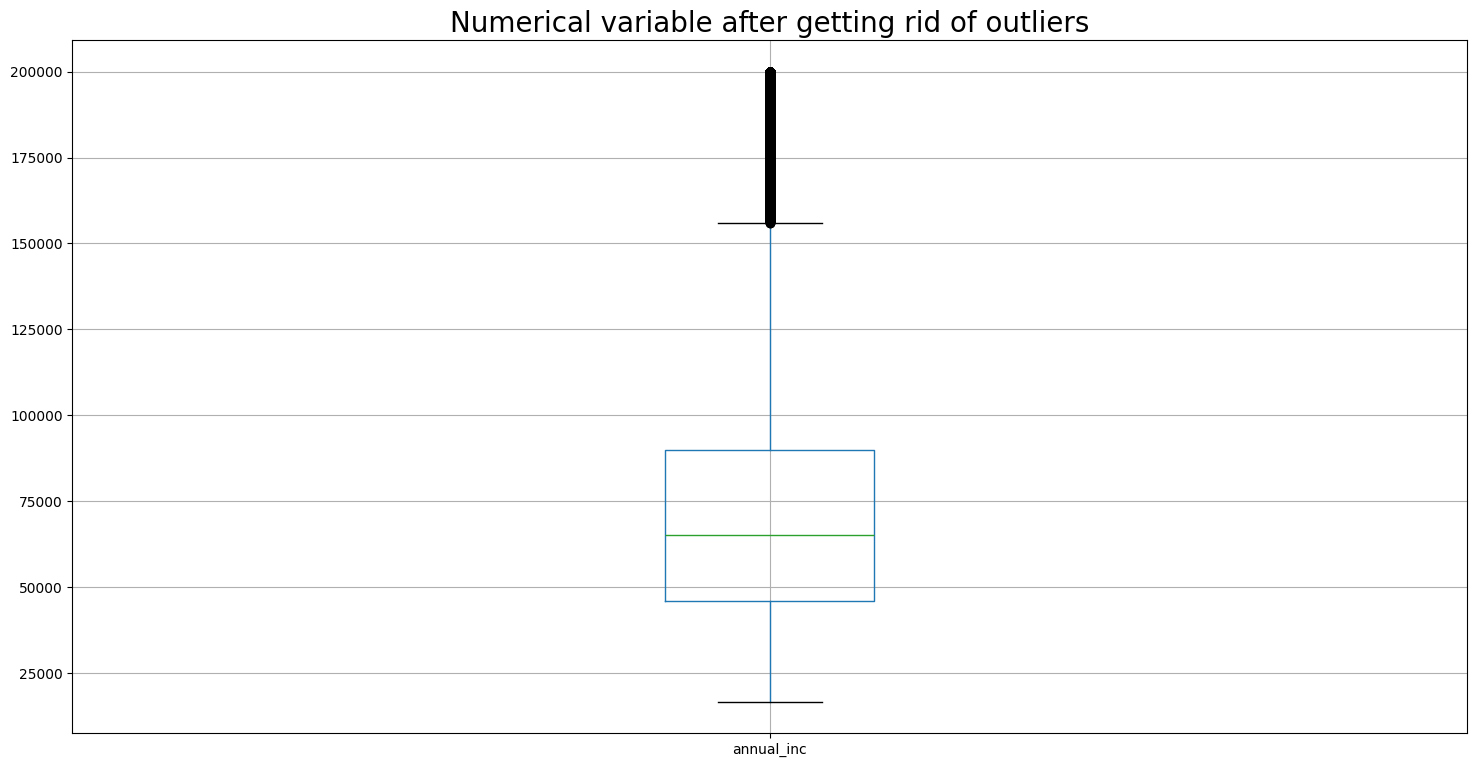

In [69]:
plt.figure(figsize=(18,9))
loan[num_cols].boxplot()
plt.title("Numerical variable after getting rid of outliers", fontsize=20)
plt.show()

In [70]:
int_default = pd.crosstab(loan['int_rate'], loan['target'])
int_default['percent_default'] = int_default[1]/(int_default[0]+int_default[1])
int_default

target,0,1,percent_default
int_rate,,,
5.31,1322,4,0.003017
5.32,7475,151,0.019801
5.42,122,1,0.008130
5.79,67,2,0.028986
5.93,285,7,0.023973
...,...,...,...
30.79,201,60,0.229885
30.84,88,48,0.352941
30.89,89,35,0.282258


## Looking at the distribution of defaut rate by credit grade

In [71]:
ct = pd.crosstab(loan['grade'], loan['target'])
ct['percent_default'] = ct[1] / (ct[1] + ct[0])
ct

target,0,1,percent_default
grade,,,
A,68730,2434,0.034203
B,102090,8964,0.080717
C,94908,14574,0.133118
D,44558,10421,0.189545
E,16564,6277,0.274813
F,4597,2452,0.347851
G,1301,763,0.369671


In [72]:
ct_reset = ct.reset_index()
ct_reset

target,grade,0,1,percent_default
0,A,68730,2434,0.034203
1,B,102090,8964,0.080717
2,C,94908,14574,0.133118
3,D,44558,10421,0.189545
4,E,16564,6277,0.274813
5,F,4597,2452,0.347851
6,G,1301,763,0.369671


/tmp/ipykernel_925/2843142931.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=ct_reset, x='grade', y='percent_default', palette='Reds')


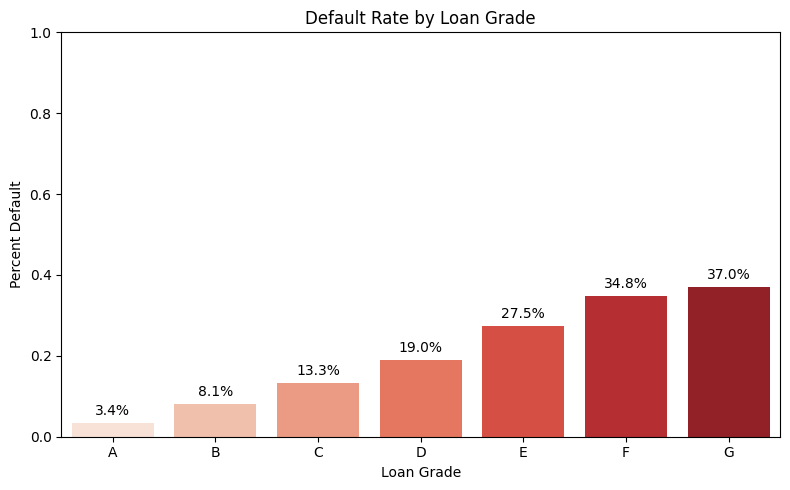

In [73]:
plt.figure(figsize=(8,5))
ax = sns.barplot(data=ct_reset, x='grade', y='percent_default', palette='Reds')


plt.title('Default Rate by Loan Grade')
plt.ylabel('Percent Default')
plt.xlabel('Loan Grade')
plt.ylim(0, 1)  # since percent_default is between 0 and 1

for p in ax.patches:
    height = p.get_height()
    ax.text(
        x=p.get_x() + p.get_width() / 2,
        y=height + 0.02,
        s=f'{height * 100:.1f}%',
        ha='center'
    )

plt.tight_layout()
plt.show()

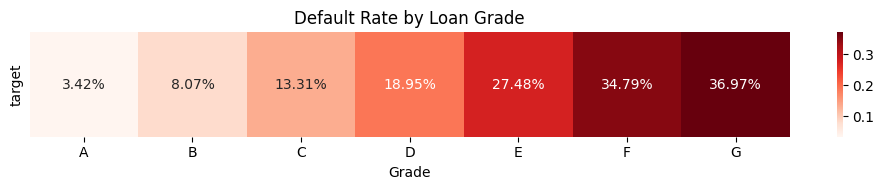

In [74]:
heatmap_data = ct[['percent_default']].T  # Transpose to make it horizontal
plt.figure(figsize=(10, 2))
sns.heatmap(heatmap_data, annot=True, cmap='Reds', fmt=".2%")

plt.title('Default Rate by Loan Grade')
plt.xlabel('Grade')
plt.yticks([])
plt.tight_layout()
plt.show()

## Part 1: Exploring Multicollinerarity

### Assessing Multicollinearity using the Correlation Matrix

In [75]:
indpt_var = loan.drop(columns='target').select_dtypes(include='number')
feature_corr = indpt_var.corr()
collinear_features = feature_corr.where(feature_corr.abs() > 0.8)
collinear_features

,member_id,loan_amnt,funded_amnt,funded_amnt_inv,int_rate,installment,annual_inc,dti,delinq_2yrs,fico_range_low,...,deferral_term,hardship_amount,hardship_length,hardship_dpd,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,settlement_amount,settlement_percentage,settlement_term
member_id,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan_amnt,NaN,1.000000,0.999688,0.998952,NaN,0.942771,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.852165,NaN,NaN,NaN,NaN
funded_amnt,NaN,0.999688,1.000000,0.999325,NaN,0.943188,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.852165,NaN,NaN,NaN,NaN
funded_amnt_inv,NaN,0.998952,0.999325,1.000000,NaN,0.942315,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.852159,NaN,NaN,NaN,NaN
int_rate,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
hardship_payoff_balance_amount,NaN,0.852165,0.852165,0.852159,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.888429,NaN,NaN,0.886274,1.000000,NaN,0.94811,NaN,NaN
hardship_last_payment_amount,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN
settlement_amount,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.862014,NaN,NaN,NaN,0.948110,NaN,1.00000,NaN,NaN
settlement_percentage,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN


In [76]:
collinear_features.loc['loan_amnt'][collinear_features.loc['loan_amnt'].notnull()]


,loan_amnt
loan_amnt,1.000000
funded_amnt,0.999688
funded_amnt_inv,0.998952
installment,0.942771
hardship_payoff_balance_amount,0.852165


In [77]:
for feature in collinear_features.index:
    non_null_corrs = collinear_features.loc[feature].dropna()
    print(f"\n - {feature.upper()} (correlated with {len(non_null_corrs)} features):")
    print(non_null_corrs.to_string())


 - MEMBER_ID (correlated with 0 features):
Series([], )

 - LOAN_AMNT (correlated with 5 features):
loan_amnt                         1.000000
funded_amnt                       0.999688
funded_amnt_inv                   0.998952
installment                       0.942771
hardship_payoff_balance_amount    0.852165

 - FUNDED_AMNT (correlated with 5 features):
loan_amnt                         0.999688
funded_amnt                       1.000000
funded_amnt_inv                   0.999325
installment                       0.943188
hardship_payoff_balance_amount    0.852165

 - FUNDED_AMNT_INV (correlated with 5 features):
loan_amnt                         0.998952
funded_amnt                       0.999325
funded_amnt_inv                   1.000000
installment                       0.942315
hardship_payoff_balance_amount    0.852159

 - INT_RATE (correlated with 1 features):
int_rate    1.0

 - INSTALLMENT (correlated with 4 features):
loan_amnt          0.942771
funded_amnt        0.9431

### Dropping features that are too highly correlated (threshold: 0.8)

In [78]:
def drop_high_corr(df, threshold=0.8):
    corr_matrix = df.select_dtypes(include='number').drop(columns='target', errors='ignore').corr().abs()
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    to_drop = upper.columns[upper.gt(threshold).any()].tolist()
    return df.drop(columns=to_drop)

df_reduced = drop_high_corr(loan)  # diagnostic only; do not overwrite model inputs

In [79]:
df_reduced.head()

,id,member_id,loan_amnt,term,int_rate,grade,sub_grade,emp_title,emp_length,home_ownership,...,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_percentage,settlement_term,target,dataset_type
0,1006259,NaN,2500.0,36 months,11.71,B,B3,NaN,2 years,OWN,...,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,0,train
1,50303671,NaN,7425.0,36 months,18.55,E,E2,New Patient Check in,1 year,MORTGAGE,...,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,0,train
2,30485774,NaN,15700.0,36 months,11.67,B,B4,RN,10+ years,MORTGAGE,...,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,0,train
3,29183992,NaN,8450.0,36 months,18.99,E,E1,Assistant customer service manager,1 year,RENT,...,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,0,train
4,62644235,NaN,15000.0,36 months,7.89,A,A5,Officer,< 1 year,OWN,...,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,0,train


In [80]:
loan = df_reduced.copy()


### Now Calculating the VIF

In [81]:
# VIF diagnostic
loan_numeric = loan.select_dtypes(include='number').drop(columns='target', errors='ignore')
loan_numeric = loan_numeric.loc[:, loan_numeric.isna().mean().le(0.2)]
loan_numeric = loan_numeric.replace([np.inf, -np.inf], np.nan).dropna()
loan_numeric = loan_numeric.loc[:, loan_numeric.nunique().gt(1)]


In [82]:
loan_vif = loan_numeric.copy()

In [62]:
# The diagonal of the inverse correlation matrix equals VIF.
# Flaging linear dependencies
if len(loan_vif) > 1 and loan_vif.shape[1]:
    corr = loan_vif.corr().to_numpy()
    if np.linalg.matrix_rank(corr) < corr.shape[0]:
        print('Singular correlation matrix: exact collinearity; remove redundant columns before interpreting VIF.')
        vif_data = pd.DataFrame({'feature': loan_vif.columns, 'VIF': np.inf})
    else:
        vif_data = pd.DataFrame({'feature': loan_vif.columns, 'VIF': np.diag(np.linalg.inv(corr))})
    print(vif_data.sort_values('VIF', ascending=False))
else:
    print('Insufficient complete numeric observations for VIF.')

                       feature        VIF
23            total_rev_hi_lim  16.176528
13                 total_pymnt  13.710790
11                   total_acc  13.388226
8                      pub_rec   9.690419
9                    revol_bal   8.536480
0                    loan_amnt   8.398451
24              bc_open_to_buy   6.931836
37                   num_il_tl   5.629755
36                   num_bc_tl   5.430104
12                   out_prncp   5.416863
43                   tax_liens   5.318615
42        pub_rec_bankruptcies   5.104525
14               total_rec_int   5.065537
20              acc_now_delinq   4.314636
39                num_tl_30dpd   3.687071
7                     open_acc   3.566509
35              num_actv_bc_tl   2.545047
17             last_pymnt_amnt   2.517719
5               fico_range_low   2.443182
10                  revol_util   2.425129
41              pct_tl_nvr_dlq   2.291151
4                  delinq_2yrs   2.255662
1                     int_rate   2

In [63]:
loan['total_acc'].nunique()

120

In [64]:
loan['total_acc']

,total_acc
0,3.0
1,12.0
2,28.0
3,8.0
4,16.0
...,...
399995,38.0
399996,20.0
399997,33.0
399998,21.0


### List of columns I dropped for the purpose of using Linear models based on:
### - the Lending Club dataset data dictionary, and
### - the above Multicollinearity analysis.
### - Post Loan Information that could create information leakage


### - ID / Administrative Fields

- id: unique loan ID, meaningless for prediction
- member_id: internal customer ID, also unique
- url Link: to loan listing, this is metadata
- policy_code: constant (always 1)
- application_type: often not predictive (joint vs individual)
- disbursement method (payment method used by investor to provide the loan: credit card, cash...)

### - Text Fields

- emp_title: essy & hard to use without NLP
- desc: User-submitted loan description
- title: Loan title — this information isn't important  (there is already a purpose column)

### - Collinear & Redundant Information (all these are highly correlated to "loan_amnt")

- funded_amnt                       
- funded_amnt_inv                  
- installment                       
- hardship_payoff_balance_amount    
- settlement_amount  
- FICO_scores    
- grade (however I will preserve the sub-grade feature as it carries more granular information than Grade)
- zip_code as there are other features conveying geographic data such as 'state'.

### - Column that was encoded to serve as the new Target Feature:\
- loan_status

### - Post-loan information which could represent a form of information leakage, my aim here is to predict loan default before default is known. Some of the below column column are cofounding variables of default as provide information that one wouldn't have ahead of a customer defaulting (in particular at the time the loan was issued)
- total_pymnt: total paid — outcome data
- total_pymnt_inv: Investor perspective — post-outcome
- total_rec_prncp: Total principal received
- total_rec_int: Total interest received
- total_rec_late_fee: Outcome-only
- recoveries: Amount recovered after charge-off
- collection_recovery_fee: Fees recovered — not known at origination
- last_pymnt_d: Last payment date — post-issue
- last_pymnt_amnt: Amount of last payment
- next_pymnt_d: Next scheduled payment — dynamic
- last_credit_pull_d: Date of last credit report pull — post-loan
- hardship_flag: flag indicating post-loan hardship event
- debt_settlement_flag: indicates whether loan ended in debt settlement — outcome data

- out_prncp: remaining principal — only known post-issue
- out_prncp_inv: rame, investor view



In [83]:
columns_to_drop = [
    'id',                    # Unique loan ID, not predictive
    'member_id',             # Internal customer ID, unique
    'url',                   # Link to loan listing, metadata
    'policy_code',           # Constant value (e.g. always 1)
    'application_type',      # Often not predictive
    'disbursement_method',    # Not useful for model
    'initial_list_status',   # Not useful for modelling credit risk - refers to the status of the loan at the time it was listed on the platform
                             #(i.ewhether it was listed as a whole loan or a fractional loan.

    # Text fields
    'emp_title',             # Free text, messy
    'desc',                  # User-submitted description
    'title',                 # Redundant with 'purpose'

    # Collinear and redundant features
    'funded_amnt',
    'funded_amnt_inv',
    'installment',
    'hardship_payoff_balance_amount',
    'settlement_amount',
    'FICO_scores',
    'grade',
    'zip_code',

    # the target feature corresponds to the encoded loan_status feature
    'loan_status',

    # Post-loan outcome variables
    'total_pymnt',
    'total_pymnt_inv',
    'total_rec_prncp',
    'total_rec_int',
    'total_rec_late_fee',
    'recoveries',
    'collection_recovery_fee',
    'last_pymnt_d',
    'last_pymnt_amnt',
    'next_pymnt_d',
    'last_credit_pull_d',
    'hardship_flag',
    'debt_settlement_flag',


    # Remaining principal
    'out_prncp',
    'out_prncp_inv'
]


### Dropping features with "too many" null values

In [84]:
#Identifying features with a lot of missing values.
missing_percent = ((loan.isnull().sum() / loan.shape[0]) * 100).sort_values(ascending=False)
missing_percent = missing_percent.round(2).astype(str) + '%'
print(missing_percent)

member_id               100.0%
hardship_status          99.5%
deferral_term            99.5%
hardship_amount          99.5%
hardship_length          99.5%
                         ...  
hardship_flag             0.0%
disbursement_method       0.0%
debt_settlement_flag      0.0%
target                    0.0%
dataset_type              0.0%
Length: 124, dtype: object


In [85]:

def removing_highnull_features(df,percent):
    max_nulls = df.shape[0]*percent

    columns = df.columns.to_list()
    col_to_drop = []

    for col in columns:
        if df[col].isnull().sum()> max_nulls:
            col_to_drop.append(col)

    return df.drop(columns=col_to_drop)

#We will drop features with 65% or more null values
df_nonull = removing_highnull_features(loan,0.65)
loan_clean = df_nonull
loan_clean.info(verbose=True)

<class 'pandas.core.frame.DataFrame'>
Index: 378633 entries, 0 to 399999
Data columns (total 87 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   id                          378633 non-null  object 
 1   loan_amnt                   378633 non-null  float64
 2   term                        378633 non-null  object 
 3   int_rate                    378633 non-null  float64
 4   grade                       378633 non-null  object 
 5   sub_grade                   378633 non-null  object 
 6   emp_title                   352313 non-null  object 
 7   emp_length                  355524 non-null  object 
 8   home_ownership              378633 non-null  object 
 9   annual_inc                  378633 non-null  float64
 10  verification_status         378633 non-null  object 
 11  issue_d                     378633 non-null  object 
 12  loan_status                 378633 non-null  object 
 13  pymnt_plan         

In [86]:
remaining_null = loan_clean.isnull().mean() * 100
remaining_null.sort_values(ascending=False)

,0
next_pymnt_d,60.311700
mths_since_last_delinq,51.138702
il_util,47.729332
mths_since_rcnt_il,40.995106
all_util,39.140804
...,...
hardship_flag,0.000000
disbursement_method,0.000000
debt_settlement_flag,0.000000
target,0.000000


In [87]:
loan_final = loan_clean.drop(columns=[col for col in columns_to_drop if col in loan_clean.columns])
loan_final.columns

Index(['loan_amnt', 'term', 'int_rate', 'sub_grade', 'emp_length',
       'home_ownership', 'annual_inc', 'verification_status', 'issue_d',
       'pymnt_plan', 'purpose', 'addr_state', 'dti', 'delinq_2yrs',
       'earliest_cr_line', 'fico_range_low', 'inq_last_6mths',
       'mths_since_last_delinq', 'open_acc', 'pub_rec', 'revol_bal',
       'revol_util', 'total_acc', 'last_fico_range_high',
       'collections_12_mths_ex_med', 'acc_now_delinq', 'tot_coll_amt',
       'tot_cur_bal', 'open_acc_6m', 'open_act_il', 'open_il_12m',
       'open_il_24m', 'mths_since_rcnt_il', 'total_bal_il', 'il_util',
       'open_rv_12m', 'open_rv_24m', 'max_bal_bc', 'all_util',
       'total_rev_hi_lim', 'inq_fi', 'total_cu_tl', 'inq_last_12m',
       'bc_open_to_buy', 'chargeoff_within_12_mths', 'delinq_amnt',
       'mo_sin_old_il_acct', 'mo_sin_old_rev_tl_op', 'mo_sin_rcnt_rev_tl_op',
       'mo_sin_rcnt_tl', 'mort_acc', 'mths_since_recent_bc',
       'mths_since_recent_inq', 'num_accts_ever_120_pd'

In [88]:
loan_final.info()

<class 'pandas.core.frame.DataFrame'>
Index: 378633 entries, 0 to 399999
Data columns (total 65 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   loan_amnt                   378633 non-null  float64
 1   term                        378633 non-null  object 
 2   int_rate                    378633 non-null  float64
 3   sub_grade                   378633 non-null  object 
 4   emp_length                  355524 non-null  object 
 5   home_ownership              378633 non-null  object 
 6   annual_inc                  378633 non-null  float64
 7   verification_status         378633 non-null  object 
 8   issue_d                     378633 non-null  object 
 9   pymnt_plan                  378633 non-null  object 
 10  purpose                     378633 non-null  object 
 11  addr_state                  378633 non-null  object 
 12  dti                         378633 non-null  float64
 13  delinq_2yrs        

### Now I am going to encode categorical columns

In [89]:
loan_final.select_dtypes(include=[object])

,term,sub_grade,emp_length,home_ownership,verification_status,issue_d,pymnt_plan,purpose,addr_state,earliest_cr_line,dataset_type
0,36 months,B3,2 years,OWN,Source Verified,Nov-2011,n,major_purchase,FL,Nov-2007,train
1,36 months,E2,1 year,MORTGAGE,Source Verified,Jun-2015,n,debt_consolidation,FL,Jul-2005,train
2,36 months,B4,10+ years,MORTGAGE,Source Verified,Oct-2014,n,debt_consolidation,DE,Nov-1998,train
3,36 months,E1,1 year,RENT,Not Verified,Oct-2014,n,debt_consolidation,MD,Aug-2011,train
4,36 months,A5,< 1 year,OWN,Not Verified,Oct-2015,n,debt_consolidation,MD,Oct-2005,train
...,...,...,...,...,...,...,...,...,...,...,...
399995,36 months,C3,4 years,MORTGAGE,Source Verified,Mar-2016,n,renewable_energy,TX,Jun-1998,test
399996,36 months,A5,10+ years,MORTGAGE,Not Verified,Oct-2012,n,debt_consolidation,TX,Jan-1995,test
399997,60 months,C3,3 years,MORTGAGE,Verified,Jul-2018,n,credit_card,TX,Jun-2001,test
399998,36 months,B5,10+ years,RENT,Source Verified,Nov-2017,n,debt_consolidation,NY,Nov-2002,test


#### Reviewing the last potentially irrelevant object-type columns before encoding them.

In [90]:
# Looking at the payment_plan feature:

print(loan_final['pymnt_plan'].value_counts())

pymnt_plan
n    378519
y       114
Name: count, dtype: int64


In [91]:
# Given the few "y" values, this feature is irrelevant, let's drop it.
loan_final = loan_final.drop('pymnt_plan', axis=1)
loan_final.select_dtypes(include=[object])

,term,sub_grade,emp_length,home_ownership,verification_status,issue_d,purpose,addr_state,earliest_cr_line,dataset_type
0,36 months,B3,2 years,OWN,Source Verified,Nov-2011,major_purchase,FL,Nov-2007,train
1,36 months,E2,1 year,MORTGAGE,Source Verified,Jun-2015,debt_consolidation,FL,Jul-2005,train
2,36 months,B4,10+ years,MORTGAGE,Source Verified,Oct-2014,debt_consolidation,DE,Nov-1998,train
3,36 months,E1,1 year,RENT,Not Verified,Oct-2014,debt_consolidation,MD,Aug-2011,train
4,36 months,A5,< 1 year,OWN,Not Verified,Oct-2015,debt_consolidation,MD,Oct-2005,train
...,...,...,...,...,...,...,...,...,...,...
399995,36 months,C3,4 years,MORTGAGE,Source Verified,Mar-2016,renewable_energy,TX,Jun-1998,test
399996,36 months,A5,10+ years,MORTGAGE,Not Verified,Oct-2012,debt_consolidation,TX,Jan-1995,test
399997,60 months,C3,3 years,MORTGAGE,Verified,Jul-2018,credit_card,TX,Jun-2001,test
399998,36 months,B5,10+ years,RENT,Source Verified,Nov-2017,debt_consolidation,NY,Nov-2002,test


### Let's now create a new feature, "credit-history_years' using both features: earliest_cr_line and 'issue_d'. This feature will be interesting as it will provide us an idea of the borrower's cedit history.

In [92]:
import pandas as pd

def transform_earliest_cr_line(df, cr_col='earliest_cr_line', issue_col='issue_d'):

    df[cr_col] = pd.to_datetime(df[cr_col], format='%b-%Y', errors='coerce')
    df[issue_col] = pd.to_datetime(df[issue_col], format='%b-%Y', errors='coerce')

    # Calculating credit history in years relative to issue date
    df['credit_history_years'] = df[issue_col].dt.year - df[cr_col].dt.year
    df = df.drop([cr_col, issue_col], axis = 1)

    return df


In [93]:
loan_final = transform_earliest_cr_line(loan_final)

In [76]:
loan_final[['credit_history_years']].head()

,credit_history_years
0,4.0
1,10.0
2,16.0
3,3.0
4,10.0


### Now, I am converting the 'term' columns to integers.

In [94]:
loan_final['term'].unique()

array([' 36 months', ' 60 months'], dtype=object)

In [95]:
def transform_term (df, term_col='term'):
    loan_final[term_col] = loan_final[term_col].str.strip().replace({'36 months': 36, '60 months': 60})
    return df

In [96]:
loan_final = transform_term(loan_final)
loan_final[['term']].head()

/tmp/ipykernel_925/1216122683.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  loan_final[term_col] = loan_final[term_col].str.strip().replace({'36 months': 36, '60 months': 60})


,term
0,36
1,36
2,36
3,36
4,36


In [97]:
loan_final[loan_final['term'].isnull()]

,loan_amnt,term,int_rate,sub_grade,emp_length,home_ownership,annual_inc,verification_status,purpose,addr_state,...,num_il_tl,num_tl_120dpd_2m,num_tl_30dpd,num_tl_90g_dpd_24m,pct_tl_nvr_dlq,pub_rec_bankruptcies,tax_liens,target,dataset_type,credit_history_years


In [81]:
loan_final['term'].isnull().sum()

np.int64(0)

### Manually encoding the following ordinal features: 'sub_grade_col' and 'emp_length'. I manually created an integer "hierarchy" in order to preserve the 'order' of these variables

In [98]:
def manually_encode_ordinal(df, sub_grade_col='sub_grade', emp_length_col='emp_length'):
    cleaner_app_type = {
    sub_grade_col: {"A1": 1.0, "A2": 2.0, "A3": 3.0, "A4": 4.0, "A5": 5.0, "B1": 11.0, "B2": 12.0, "B3": 13.0, "B4": 14.0, "B5": 15.0, "C1": 21.0, "C2": 22.0, "C3": 23.0, "C4": 24.0, "C5": 25.0, "D1": 31.0, "D2": 32.0, "D3": 33.0, "D4": 34.0, "D5": 35.0, "E1": 41.0, "E2": 42.0, "E3": 43.0, "E4": 44.0, "E5": 45.0, "F1": 51.0, "F2": 52.0, "F3": 53.0, "F4": 54.0, "F5": 55.0, "G1": 61.0, "G2": 62.0, "G3": 63.0, "G4": 64.0, "G5": 65.0, },
    emp_length_col: {"< 1 year": 0.0, '1 year': 1.0, '2 years': 2.0, '3 years': 3.0, '4 years': 4.0, '5 years': 5.0, '6 years': 6.0, '7 years': 7.0, '8 years': 8.0, '9 years': 9.0, '10+ years': 10.0 }  }


    df = df.replace(cleaner_app_type)
    return df

In [99]:

loan_final = manually_encode_ordinal(loan_final)

/tmp/ipykernel_925/4292689559.py:7: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.replace(cleaner_app_type)


In [100]:
loan_final[['sub_grade','emp_length']]

,sub_grade,emp_length
0,13.0,2.0
1,42.0,1.0
2,14.0,10.0
3,41.0,1.0
4,5.0,0.0
...,...,...
399995,23.0,4.0
399996,5.0,10.0
399997,23.0,3.0
399998,15.0,10.0


In [85]:
loan_final.info()

<class 'pandas.core.frame.DataFrame'>
Index: 378633 entries, 0 to 399999
Data columns (total 63 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   loan_amnt                   378633 non-null  float64
 1   term                        378633 non-null  int64  
 2   int_rate                    378633 non-null  float64
 3   sub_grade                   378633 non-null  float64
 4   emp_length                  355524 non-null  float64
 5   home_ownership              378633 non-null  object 
 6   annual_inc                  378633 non-null  float64
 7   verification_status         378633 non-null  object 
 8   purpose                     378633 non-null  object 
 9   addr_state                  378633 non-null  object 
 10  dti                         378633 non-null  float64
 11  delinq_2yrs                 378630 non-null  float64
 12  fico_range_low              378633 non-null  float64
 13  inq_last_6mths     

### Performing "One Hot Encoding" for the following columns:
- home_ownership,
- verification_status,
- purpose
- addr_state.


In [101]:
loan_final.select_dtypes(object)

,home_ownership,verification_status,purpose,addr_state,dataset_type
0,OWN,Source Verified,major_purchase,FL,train
1,MORTGAGE,Source Verified,debt_consolidation,FL,train
2,MORTGAGE,Source Verified,debt_consolidation,DE,train
3,RENT,Not Verified,debt_consolidation,MD,train
4,OWN,Not Verified,debt_consolidation,MD,train
...,...,...,...,...,...
399995,MORTGAGE,Source Verified,renewable_energy,TX,test
399996,MORTGAGE,Not Verified,debt_consolidation,TX,test
399997,MORTGAGE,Verified,credit_card,TX,test
399998,RENT,Source Verified,debt_consolidation,NY,test


In [102]:
cat_columns = loan_final.select_dtypes(object).columns

loans_final_encoded = pd.get_dummies(loan_final, prefix_sep="__", columns=cat_columns)
loans_final_encoded

,loan_amnt,term,int_rate,sub_grade,emp_length,annual_inc,dti,delinq_2yrs,fico_range_low,inq_last_6mths,...,addr_state__TX,addr_state__UT,addr_state__VA,addr_state__VT,addr_state__WA,addr_state__WI,addr_state__WV,addr_state__WY,dataset_type__test,dataset_type__train
0,2500.0,36,11.71,13.0,2.0,27600.0,1.48,0.0,740.0,0.0,...,False,False,False,False,False,False,False,False,False,True
1,7425.0,36,18.55,42.0,1.0,26000.0,14.27,0.0,660.0,1.0,...,False,False,False,False,False,False,False,False,False,True
2,15700.0,36,11.67,14.0,10.0,68000.0,11.05,0.0,675.0,2.0,...,False,False,False,False,False,False,False,False,False,True
3,8450.0,36,18.99,41.0,1.0,25000.0,11.23,0.0,690.0,1.0,...,False,False,False,False,False,False,False,False,False,True
4,15000.0,36,7.89,5.0,0.0,40000.0,19.29,0.0,720.0,0.0,...,False,False,False,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
399995,12000.0,36,13.67,23.0,4.0,61500.0,34.87,0.0,685.0,0.0,...,True,False,False,False,False,False,False,False,True,False
399996,9600.0,36,8.90,5.0,10.0,41000.0,10.24,0.0,715.0,0.0,...,True,False,False,False,False,False,False,False,True,False
399997,35000.0,60,15.02,23.0,3.0,64000.0,33.26,0.0,685.0,0.0,...,True,False,False,False,False,False,False,False,True,False
399998,8000.0,36,11.99,15.0,10.0,42925.0,22.81,0.0,660.0,2.0,...,False,False,False,False,False,False,False,False,True,False


### Looking again at the distribution of the Numerical (type float) features still present in the Dataset

In [103]:
loans_final_encoded = loans_final_encoded.dropna()

In [104]:
float_columns = loans_final_encoded.select_dtypes(float).columns.to_list()
loans_float = loans_final_encoded[float_columns]

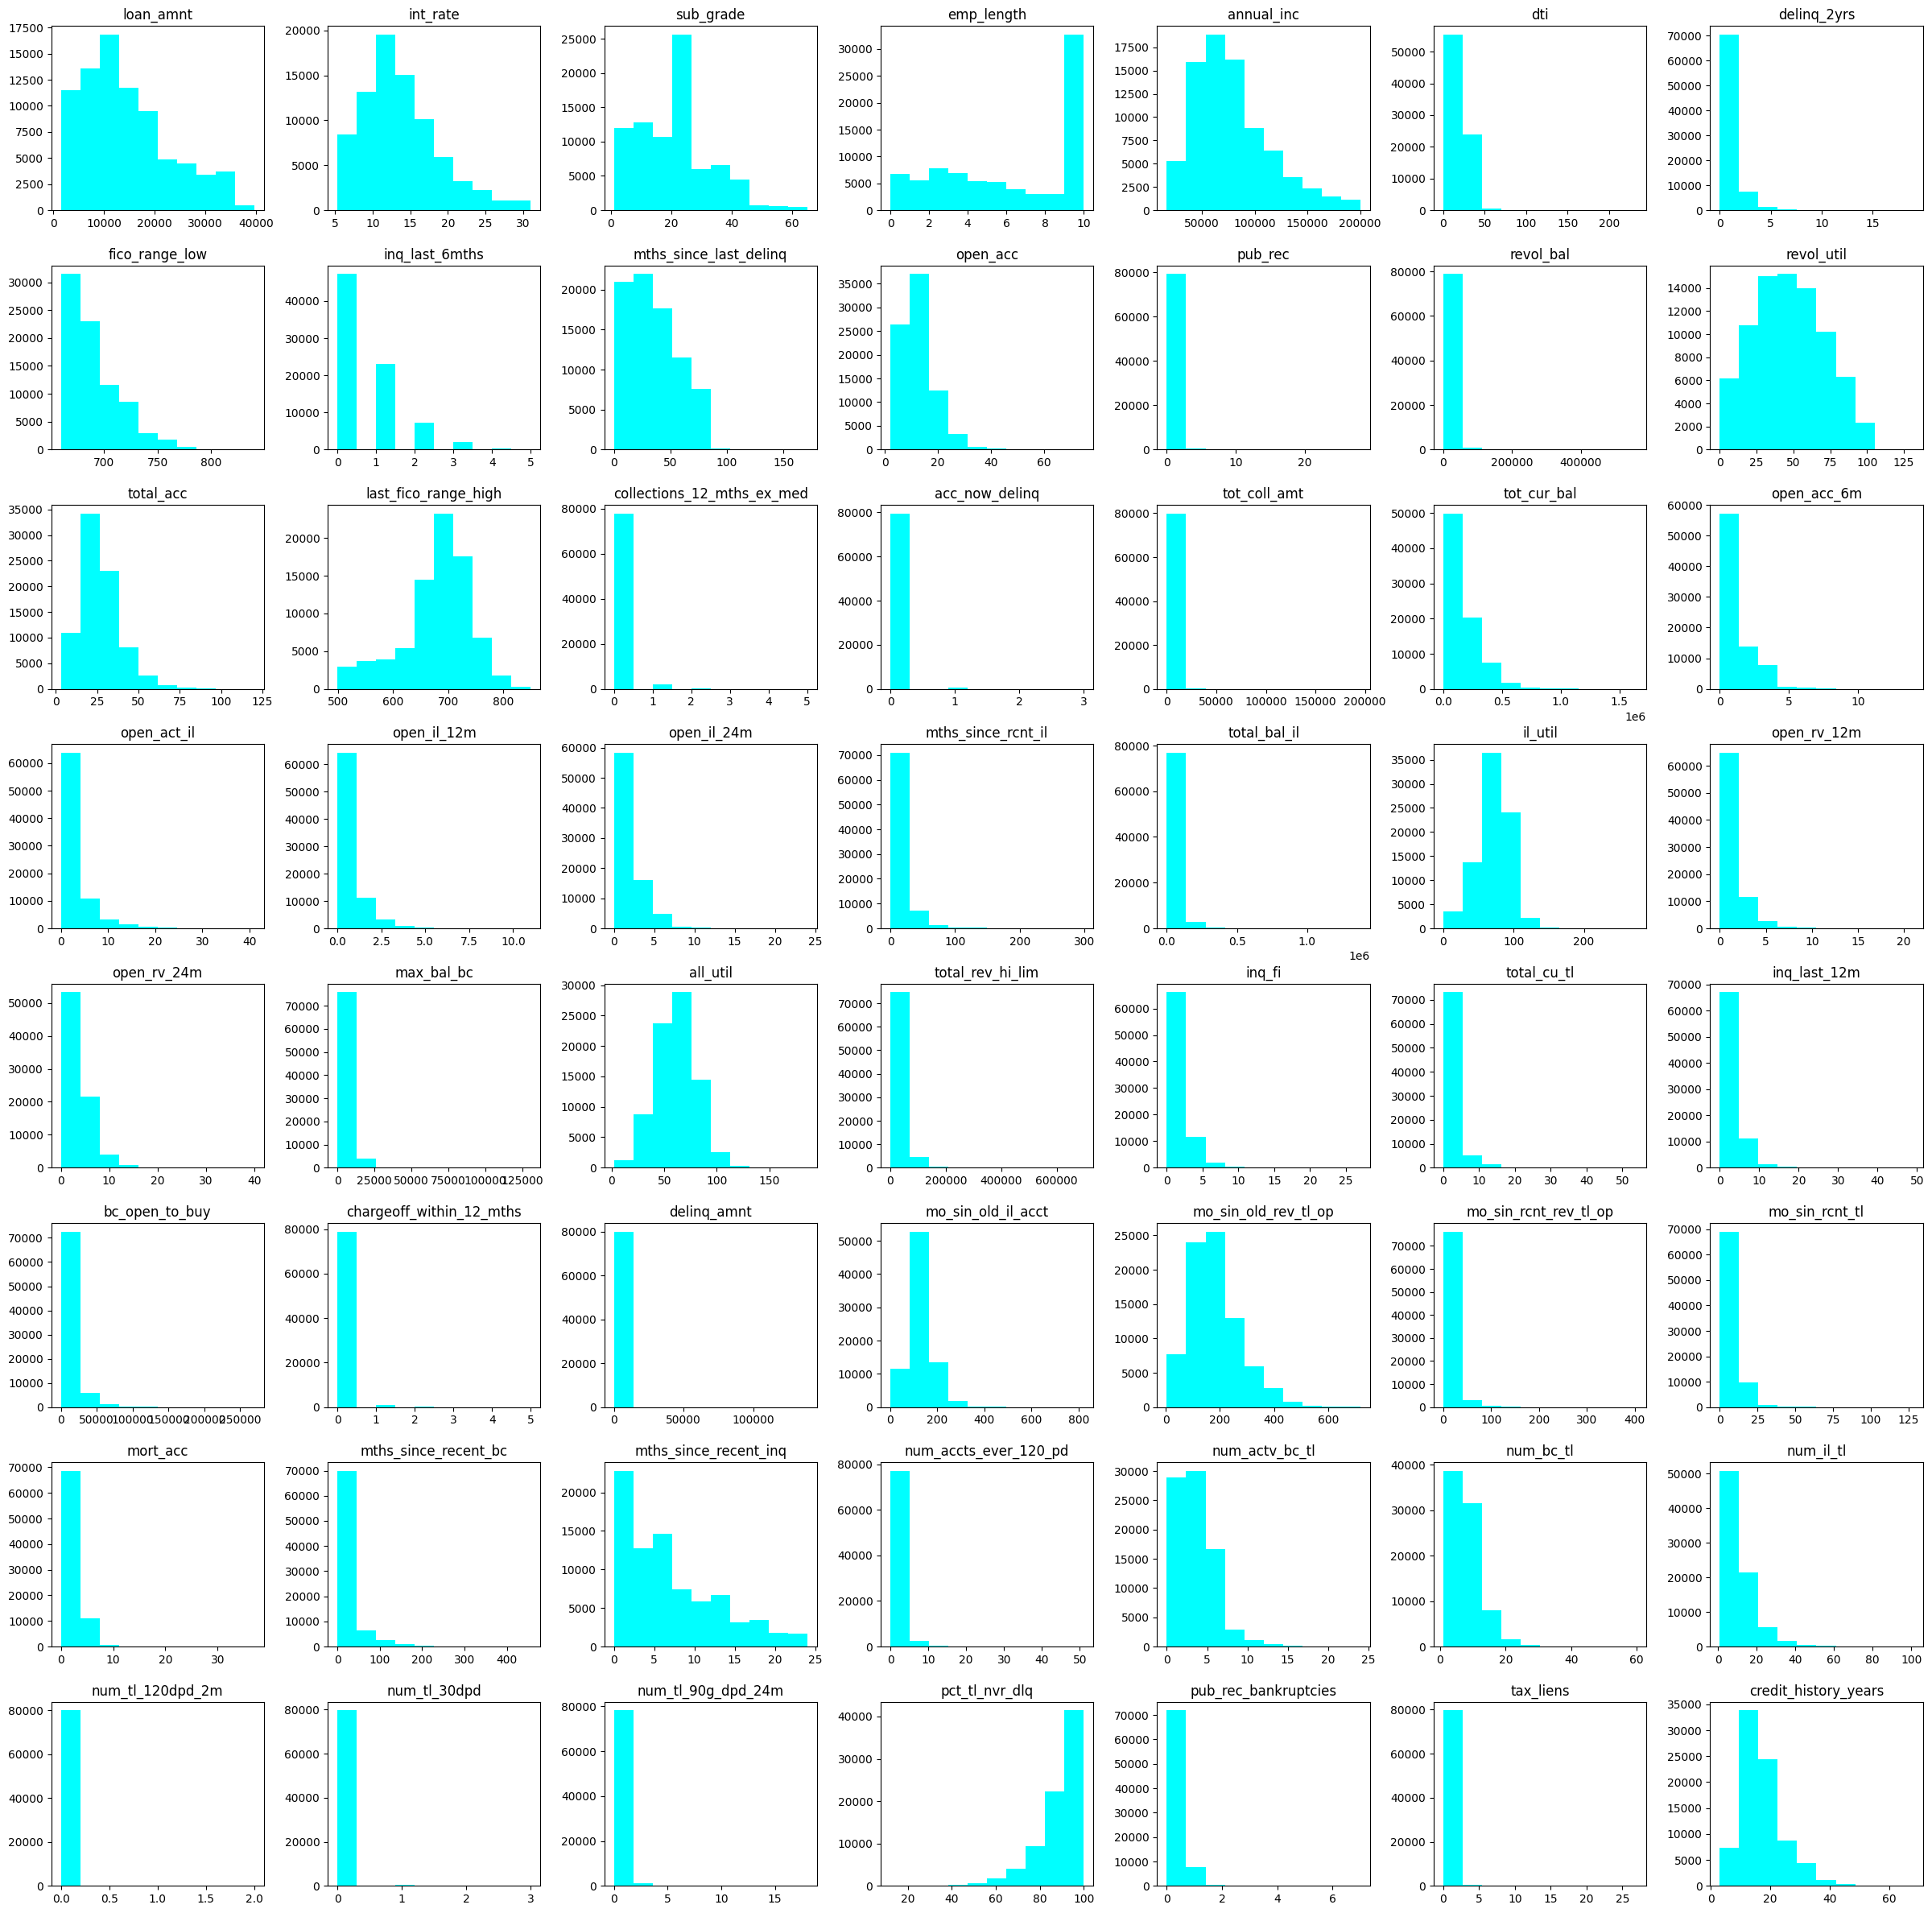

In [90]:
loans_float.hist(bins = 10, figsize = (30,30), color = 'cyan', grid=False)
None

### Using MinMaxScaler to scale the feature, and the range of int_rate is now between 0 and 1, and the shape remains the same.

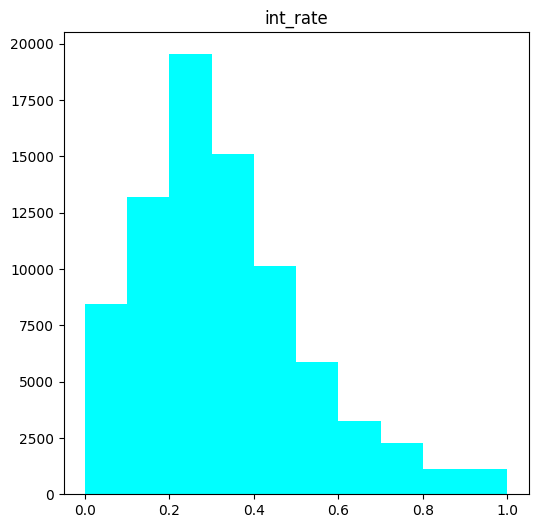

In [105]:
import sklearn.preprocessing as preprocessing
from sklearn.preprocessing import MinMaxScaler

loans = loans_final_encoded.copy()
scaler = preprocessing.MinMaxScaler()
scaled_mms = scaler.fit_transform(loans[['int_rate']])
scaled_mms = pd.DataFrame(scaled_mms, columns=['int_rate'])
scaled_mms.hist(bins = 10, figsize = (6,6), color = 'cyan', grid=False)
None

### Using Standard Scaler to centre the distribution around zero assuming the distribution of interest rates is normally distributed

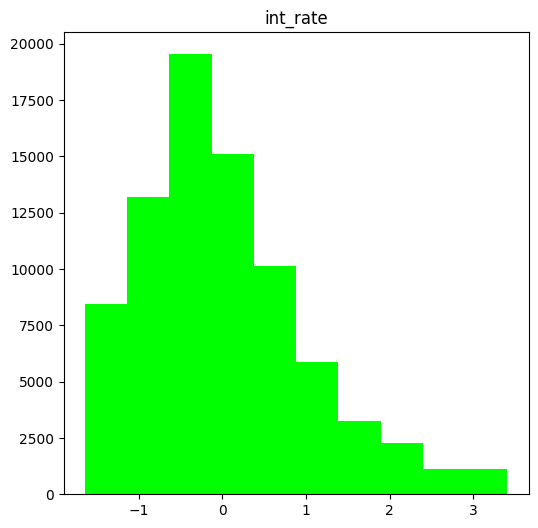

In [106]:
from sklearn import preprocessing


scaler = preprocessing.StandardScaler()
scaled_sc = scaler.fit_transform(loans[['int_rate']])
scaled_sc = pd.DataFrame(scaled_sc, columns=['int_rate'])
scaled_sc.hist(bins = 10, figsize = (6,6), color = 'lime', grid=False)
None


# Regression Part 2 - Lasso, Ridge and ElasticNet

#### Since my target variable is binary, I should used logistic regression (rather then OLS) on this dataset. However, for the purpose of completing week 2 homework in line with its instructions, I implemented both:
#### - A) Standard OLS Regression, Lasso, Ridge and Elastic Net, and
#### - B) Logistic Regression with L1 (Lasso), L2 (Ridge), and Elastic Net penalties.
         
#### I evaluated predictive performance using the typicall metrics used for Regression and Classification:
#### - MSE, MAE and R^2 (regression)
#### - accuracy, recall, confusion matrix...(classification)

In [107]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

### Performing Forward Feature Selection using a simple Linear Regression, and
### repeated KFold Cross Validation as the base model.

In [108]:
from sklearn.linear_model import LinearRegression

X = loans.drop('target', axis= 1)
y = loans['target']

In [109]:
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.33, random_state=42)

In [96]:
# Forward Feature Selection: code from notebook Homework 5 of mod Machine Learning Fundamentals
from sklearn.linear_model import LinearRegression


# Forward Feature Selection function
def forward_feature_selection(X, y, model, scoring='neg_mean_squared_error', cv=5, tol=None, max_features=None, n_jobs=-1, verbose=False):
    selected_features = []                                  # List to store the order of features selected
    remaining_features = list(X.columns)                    # Features not yet selected
    best_scores = []                                        # List to store the CV score after each feature addition
    previous_score = float('inf')                           # Initialize previous score for improvement comparison

    # Track the best subset of features and its corresponding score
    best_feature_set = None                                  # Best combination of features found so far
    best_score = float('inf')

    while remaining_features:
        scores = {}                                          # Dictionary to hold CV scores for each candidate feature
        for feature in remaining_features:
            current_features = selected_features + [feature]

            # Compute the CV score for the current set of features (negated MSE, so lower is better)
            cv_score = -cross_val_score(model, X[current_features], y,
                                        scoring=scoring, cv=cv, n_jobs=n_jobs).mean()
            scores[feature] = cv_score

        # Select the feature that minimizes the CV score
        best_feature = min(scores, key=scores.get)
        current_score = scores[best_feature]

        # Check if the improvement is significant based on the tolerance (tol)
        if tol is not None and previous_score - current_score < tol:
            if verbose:
                print("Stopping early due to minimal improvement.")
            break

        # Add the best feature to the selected list and update score trackers
        selected_features.append(best_feature)
        best_scores.append(current_score)
        remaining_features.remove(best_feature)
        previous_score = current_score

        # Update the best subset if the current score is better than the best so far
        if verbose:
            print(f"\nFeatures: {selected_features[-3:]}, CV Score (MSE): {current_score:.4f}")

        if current_score < best_score:
            best_score = current_score
            best_feature_set = selected_features.copy()

        # Check if the maximum number of features has been reached
        if max_features is not None and len(selected_features) >= max_features:
            break

    return (selected_features, best_scores, best_feature_set, best_score)


In [101]:
model = LinearRegression()

# We comment out the long-running forward feature selection to avoid hours of execution:
# selected_features, best_scores, best_forward_features, best_score = forward_feature_selection(X, y, model, verbose=False)

# Instead, we define and load your pre-saved best features list directly to make the cell self-contained:
best_forward_features = [
    'last_fico_range_high', 'fico_range_low', 'loan_amnt', 'pct_tl_nvr_dlq',
    'annual_inc', 'mo_sin_old_rev_tl_op', 'mths_since_last_delinq',
    'num_accts_ever_120_pd', 'bc_open_to_buy', 'num_actv_bc_tl', 'num_bc_tl',
    'purpose__home_improvement', 'purpose__house', 'verification_status__Verified',
    'tot_cur_bal', 'mort_acc', 'int_rate', 'open_rv_12m', 'purpose__other',
    'addr_state__GA', 'addr_state__CT', 'pub_rec', 'addr_state__SC',
    'addr_state__IL', 'il_util', 'total_bal_il', 'total_acc', 'max_bal_bc',
    'addr_state__CA', 'addr_state__NY', 'inq_last_6mths', 'mths_since_recent_inq',
    'open_acc_6m', 'open_il_12m', 'purpose__small_business', 'acc_now_delinq',
    'purpose__credit_card', 'purpose__debt_consolidation', 'addr_state__WA',
    'num_il_tl', 'open_acc', 'open_act_il', 'all_util', 'addr_state__VT',
    'dti', 'addr_state__KS', 'addr_state__VA', 'inq_fi', 'addr_state__ME',
    'addr_state__OR', 'addr_state__NV', 'addr_state__MT', 'num_tl_120dpd_2m',
    'purpose__vacation', 'chargeoff_within_12_mths', 'purpose__major_purchase',
    'addr_state__RI', 'mths_since_recent_bc', 'addr_state__ND', 'purpose__wedding',
    'home_ownership__OTHER', 'purpose__educational', 'addr_state__IA'
]

selected_features = best_forward_features.copy()

print(f"Using pre-saved feature selection results!")
print(f"Selected features count: {len(selected_features)}")
print(f"Best Features: {selected_features}")

Using pre-saved feature selection results!
Selected features count: 63
Best Features: ['last_fico_range_high', 'fico_range_low', 'loan_amnt', 'pct_tl_nvr_dlq', 'annual_inc', 'mo_sin_old_rev_tl_op', 'mths_since_last_delinq', 'num_accts_ever_120_pd', 'bc_open_to_buy', 'num_actv_bc_tl', 'num_bc_tl', 'purpose__home_improvement', 'purpose__house', 'verification_status__Verified', 'tot_cur_bal', 'mort_acc', 'int_rate', 'open_rv_12m', 'purpose__other', 'addr_state__GA', 'addr_state__CT', 'pub_rec', 'addr_state__SC', 'addr_state__IL', 'il_util', 'total_bal_il', 'total_acc', 'max_bal_bc', 'addr_state__CA', 'addr_state__NY', 'inq_last_6mths', 'mths_since_recent_inq', 'open_acc_6m', 'open_il_12m', 'purpose__small_business', 'acc_now_delinq', 'purpose__credit_card', 'purpose__debt_consolidation', 'addr_state__WA', 'num_il_tl', 'open_acc', 'open_act_il', 'all_util', 'addr_state__VT', 'dti', 'addr_state__KS', 'addr_state__VA', 'inq_fi', 'addr_state__ME', 'addr_state__OR', 'addr_state__NV', 'addr_sta

In [102]:
import time

# Here I benchmarked a single feature iteration to estimate the total run time for forward feature selection.
start_time = time.time()
_ = -cross_val_score(model, X[['int_rate']], y, scoring='neg_mean_squared_error', cv=5, n_jobs=-1)
iteration_time = time.time() - start_time

total_features = X.shape[1]
estimated_total_time_mins = (iteration_time * total_features * (total_features + 1) / 2) / 60

print(f"Time for a single feature evaluation: {iteration_time:.2f} seconds.")
print(f"Estimated total time for full forward selection: {estimated_total_time_mins:.2f} minutes.")

Time for a single feature evaluation: 0.13 seconds.
Estimated total time for full forward selection: 20.03 minutes.


In [103]:
best_forward_features = ['last_fico_range_high', 'fico_range_low', 'loan_amnt', 'pct_tl_nvr_dlq', 'annual_inc', 'mo_sin_old_rev_tl_op', 'mths_since_last_delinq', 'num_accts_ever_120_pd', 'bc_open_to_buy', 'num_actv_bc_tl', 'num_bc_tl', 'purpose__home_improvement', 'purpose__house', 'verification_status__Verified', 'tot_cur_bal', 'mort_acc', 'int_rate', 'open_rv_12m', 'purpose__other', 'addr_state__GA', 'addr_state__CT', 'pub_rec', 'addr_state__SC', 'addr_state__IL', 'il_util', 'total_bal_il', 'total_acc', 'max_bal_bc', 'addr_state__CA', 'addr_state__NY', 'inq_last_6mths', 'mths_since_recent_inq', 'open_acc_6m', 'open_il_12m', 'purpose__small_business', 'acc_now_delinq', 'purpose__credit_card', 'purpose__debt_consolidation', 'addr_state__WA', 'num_il_tl', 'open_acc', 'open_act_il', 'all_util', 'addr_state__VT', 'dti', 'addr_state__KS', 'addr_state__VA', 'inq_fi', 'addr_state__ME', 'addr_state__OR', 'addr_state__NV', 'addr_state__MT', 'num_tl_120dpd_2m', 'purpose__vacation', 'chargeoff_within_12_mths', 'purpose__major_purchase', 'addr_state__RI', 'mths_since_recent_bc', 'addr_state__ND', 'purpose__wedding', 'home_ownership__OTHER', 'purpose__educational', 'addr_state__IA']

In [104]:
models = {
    "OLS (Linear Regression)": LinearRegression(),
    "Lasso Regression": Lasso(alpha=1.0, max_iter=10000),
    "Ridge Regression": Ridge(alpha=1.0,max_iter=10000),
    "Elastic Net Regression": ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=10000)
}

In [105]:
X_train_best = X_train[best_forward_features]
X_test_best = X_test[best_forward_features]

In [106]:
coefs = {}
def evaluate_model(name, model):
    print(f"\n----------{name}-----------")
    model.fit(X_train, y_train)
    y_pred_raw = model.predict(X_test)
    y_pred_binary = (y_pred_raw >= 0.5).astype(int)


    print("\n REGRESSION METRICS")
    print("MSE:", mean_squared_error(y_test, y_pred_raw))
    print("MAE:", mean_absolute_error(y_test, y_pred_raw))
    print("R² Score:", r2_score(y_test, y_pred_raw))


    print("\n CLASSIFICATION METRICS (Threshold = 0.5)")
    print("Accuracy :", accuracy_score(y_test, y_pred_binary))
    print("Precision:", precision_score(y_test, y_pred_binary))
    print("Recall   :", recall_score(y_test, y_pred_binary))
    print("F1 Score :", f1_score(y_test, y_pred_binary))
    print("ROC AUC  :", roc_auc_score(y_test, y_pred_raw))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_binary))

    coefs[name] = model.coef_

In [ ]:
for name, model in models.items():
    evaluate_model(name, model)


----------OLS (Linear Regression)-----------

 REGRESSION METRICS
MSE: 0.05090098908386337
MAE: 0.149290739471492
R² Score: 0.4163199123287974

 CLASSIFICATION METRICS (Threshold = 0.5)
Accuracy : 0.9349831914741434
Precision: 0.8117480537862704
Recall   : 0.42497221193034457
F1 Score : 0.5578793774319066
ROC AUC  : 0.9592154337774541
Confusion Matrix:
 [[24997   266]
 [ 1552  1147]]

----------Lasso Regression-----------

 REGRESSION METRICS
MSE: 0.05321658896702405
MAE: 0.14910985340571434
R² Score: 0.38976699917051205

 CLASSIFICATION METRICS (Threshold = 0.5)
Accuracy : 0.9209284028324154
Precision: 0.8485714285714285
Recall   : 0.22008151167098924
F1 Score : 0.34951456310679613
ROC AUC  : 0.955745366084838
Confusion Matrix:
 [[25157   106]
 [ 2105   594]]

----------Ridge Regression-----------

 REGRESSION METRICS
MSE: 0.05091289827306273
MAE: 0.14933102937278322
R² Score: 0.41618335001987017

 CLASSIFICATION METRICS (Threshold = 0.5)
Accuracy : 0.9347686145483156
Precision: 0.80

## Looking at the feature weights for each model

In [ ]:
coef_df = pd.DataFrame(coefs, index=loans.drop('target', axis=1).columns)

sorted_df =coef_df.sort_values(['Lasso Regression','Ridge Regression'], ascending=False)
sorted_df[:10]


,OLS (Linear Regression),Lasso Regression,Ridge Regression,Elastic Net Regression
loan_amnt,2.625900e-06,3.115594e-06,2.625927e-06,2.951237e-06
total_rev_hi_lim,2.002037e-07,7.841502e-07,2.002107e-07,2.816932e-07
max_bal_bc,7.741064e-07,7.787320e-07,7.740564e-07,9.564632e-07
bc_open_to_buy,2.073983e-07,5.015703e-07,2.074629e-07,1.482665e-07
delinq_amnt,1.190921e-06,3.229092e-07,1.191012e-06,1.368802e-06
acc_now_delinq,5.413336e-02,0.000000e+00,5.190850e-02,0.000000e+00
purpose__small_business,3.572581e-02,0.000000e+00,3.558918e-02,0.000000e+00
addr_state__NM,3.090180e-02,0.000000e+00,3.077085e-02,0.000000e+00
addr_state__AR,2.454593e-02,0.000000e+00,2.448158e-02,0.000000e+00
addr_state__WV,2.308700e-02,0.000000e+00,2.290272e-02,0.000000e+00


## Visual Comparison of Feature Weight Shrinkage (or not) Across Models

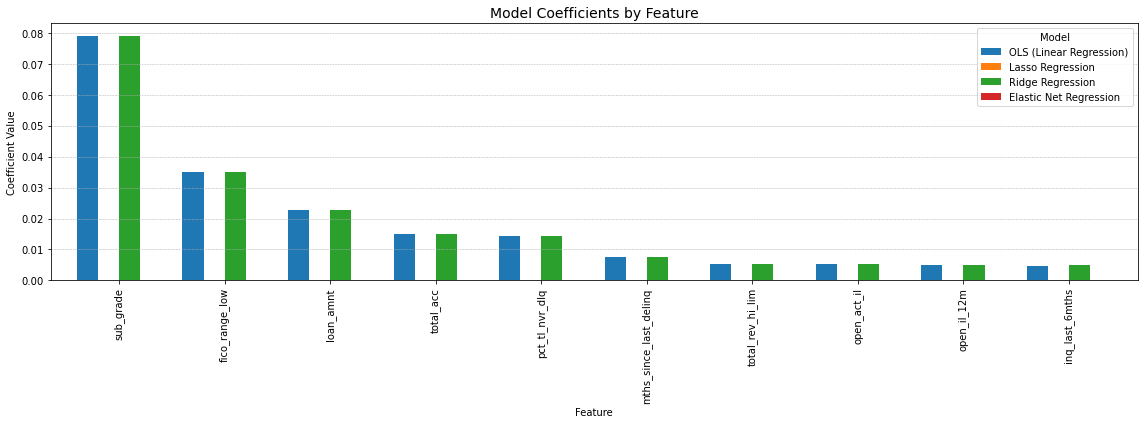

In [ ]:
sorted_df[:10].plot(kind='bar', figsize=(16, 6), width=0.8)
plt.title('Model Coefficients by Feature', fontsize=14)
plt.xlabel("Feature")
plt.ylabel("Coefficient Value")
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', linewidth=0.5)
plt.legend(title='Model')
plt.tight_layout()
plt.show()

## Trying GridSearchCV to find the best model parameters that provide the highest 'neg_mean_squared_error' score across CV folds (sweeping over the alpha parameter)

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grids = {
    "OLS (Linear Regression)": {},
    "Lasso Regression": {"alpha": [0.001, 0.01, 0.1, 1, 10]},
    "Ridge Regression": {"alpha": [0.001, 0.01, 0.1, 1, 10]},
    "Elastic Net Regression": {
        "alpha": [0.001, 0.01, 0.1, 1],
        "l1_ratio": [0.1, 0.5, 0.7, 0.9]
    }
}

scoring = "neg_mean_squared_error"

best_models = {}

for name, model in models.items():
    print(f"\n--- Grid Search for {name} ---")
    grid = GridSearchCV(model, param_grids[name], scoring=scoring, cv=5)
    grid.fit(X_train, y_train)
    best_models[name] = grid.best_estimator_

    print("Best Score:", grid.best_score_)
    print("Best Params:", grid.best_params_)



--- Grid Search for OLS (Linear Regression) ---
Best Score: -5.993476607395347e+19
Best Params: {}

--- Grid Search for Lasso Regression ---
Best Score: -0.05052225094396332
Best Params: {'alpha': 0.001}

--- Grid Search for Ridge Regression ---
Best Score: -0.05043467211819995
Best Params: {'alpha': 10}

--- Grid Search for Elastic Net Regression ---
Best Score: -0.0504255445400596
Best Params: {'alpha': 0.001, 'l1_ratio': 0.1}


In [ ]:
for name, model in best_models.items():
    evaluate_model(name, model)


----------OLS (Linear Regression)-----------

 REGRESSION METRICS
MSE: 3.6750343088906685e+18
MAE: 11798776.28582858
R² Score: -4.088741703986651e+19

 CLASSIFICATION METRICS (Threshold = 0.5)
Accuracy : 0.9331035266487367
Precision: 0.8093883357041252
Recall   : 0.4317147192716237
F1 Score : 0.5630875804057397
ROC AUC  : 0.9637349210402649
Confusion Matrix:
 [[23495   268]
 [ 1498  1138]]

----------Lasso Regression-----------

 REGRESSION METRICS
MSE: 0.052626866064503224
MAE: 0.1546395306252349
R² Score: 0.4144880184995964

 CLASSIFICATION METRICS (Threshold = 0.5)
Accuracy : 0.9317777188529869
Precision: 0.8108711839166046
Recall   : 0.41312594840667677
F1 Score : 0.5473737119879366
ROC AUC  : 0.9630912193929214
Confusion Matrix:
 [[23509   254]
 [ 1547  1089]]

----------Ridge Regression-----------

 REGRESSION METRICS
MSE: 0.05247419972959895
MAE: 0.1551301517375659
R² Score: 0.41618654199040506

 CLASSIFICATION METRICS (Threshold = 0.5)
Accuracy : 0.933065646426001
Precision: 0

In [ ]:
coef_df = pd.DataFrame(coefs, index=X.columns)

sorted_df =coef_df.sort_values(['Lasso Regression','Ridge Regression'], ascending=False)
sorted_df[:10]

,OLS (Linear Regression),Lasso Regression,Ridge Regression,Elastic Net Regression
fico_range_low,0.035063,0.033397,0.034976,0.034710
sub_grade,0.079090,0.027029,0.078293,0.070513
loan_amnt,0.022683,0.022129,0.022674,0.022538
pct_tl_nvr_dlq,0.014236,0.012994,0.014252,0.014116
num_bc_tl,0.004484,0.007236,0.004509,0.005299
mths_since_last_delinq,0.007452,0.006834,0.007475,0.007412
mo_sin_old_rev_tl_op,0.003710,0.004900,0.003683,0.003772
open_il_12m,0.004875,0.004206,0.004952,0.004892
bc_open_to_buy,0.002948,0.004204,0.002927,0.003746
mort_acc,0.003949,0.003575,0.003971,0.004175


## Visual Comparison of Feature Weight Shrinkage (or nor) Across Models with best alpha parameter from GrigSearchCV

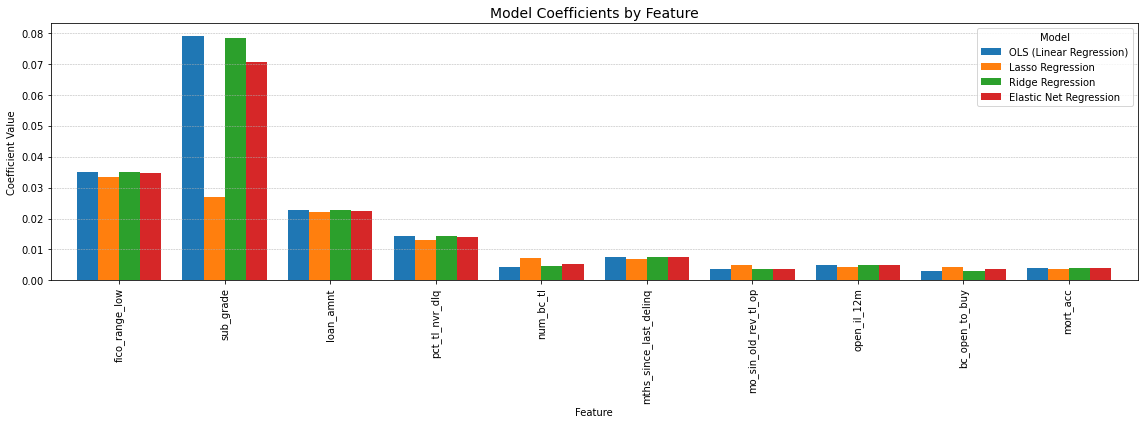

In [ ]:
sorted_df[:10].plot(kind='bar', figsize=(16, 6), width=0.8)
plt.title('Model Coefficients by Feature', fontsize=14)
plt.xlabel("Feature")
plt.ylabel("Coefficient Value")
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', linewidth=0.5)
plt.legend(title='Model')
plt.tight_layout()
plt.show()

# B. Logistic Regression
#### For all models below:
- #### I am using the 'saga' solver, as it is the only solver that supports all penalty types, from L1 to Elastic Net.
- #### I am using the hyperparameter class_weight='balanced' to rebalance the dataset, since the target feature is heavily imbalanced.

In [ ]:
simple_logit= LogisticRegression(solver='saga',class_weight='balanced')
simple_logit.fit(X_train, y_train)

/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :ter

## Performing Lasso regression (using the hyperparameter, penalty= l1)

In [ ]:
# Lasso (L1)
lasso = LogisticRegression(penalty='l1', solver='saga', class_weight='balanced', C=1.0)
lasso.fit(X_train, y_train)

/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'l1'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

## Performing Ridge regression (using the hyperparameter, penalty= l2)

In [ ]:
# Ridge (L2)
ridge = LogisticRegression(penalty='l2', solver='saga', class_weight='balanced', C=1.0)
ridge.fit(X_train, y_train)

/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'l2'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

## Performing Elastic Net regression (using the penalty='elasticnet')


In [ ]:
# As explained above, Elastic Net requires the 'saga' solver, which is why I used 'saga' for all models to ensure a fair comparison
elastic = LogisticRegression(penalty='elasticnet', solver='saga',class_weight='balanced',l1_ratio=0.5, C=1.0)
elastic.fit(X_train, y_train)

/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'elasticnet'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.5
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :ter

In [ ]:
models = {'Logit':simple_logit,'Lasso': lasso, 'Ridge': ridge,'ElasticNet': elastic}
for name, model in models.items():
    print(f"{name} score : {model.score(X_test, y_test)}")

Logit score : 0.6105786424433159
Lasso score : 0.6105786424433159
Ridge score : 0.6105071168013733
ElasticNet score : 0.6105786424433159


In [ ]:
coeffs = pd.DataFrame({
    'Feature': X.columns,
    'Logit':simple_logit.coef_[0],
    'Lasso': lasso.coef_[0],
    'Ridge': ridge.coef_[0],
    'ElasticNet': elastic.coef_[0]
})
coeffs[:10]

,Feature,Logit,Lasso,Ridge,ElasticNet
0,loan_amnt,3.836919e-05,3.836637e-05,3.836620e-05,3.836980e-05
1,int_rate,6.720609e-07,6.714405e-07,6.720246e-07,6.711713e-07
2,annual_inc,-2.907606e-06,-2.907131e-06,-2.907646e-06,-2.906958e-06
3,dti,4.113323e-07,4.095801e-07,4.107545e-07,4.097878e-07
4,delinq_2yrs,2.913885e-08,2.921136e-08,2.930536e-08,2.917256e-08
5,fico_range_low,5.010250e-06,4.979336e-06,5.014780e-06,4.975177e-06
6,fico_range_high,5.046891e-06,5.015787e-06,5.051438e-06,5.011606e-06
7,inq_last_6mths,5.092451e-08,5.086641e-08,5.091861e-08,5.084341e-08
8,mths_since_last_delinq,-9.177444e-08,-9.685006e-08,-9.408238e-08,-9.812625e-08
9,open_acc,2.072056e-07,2.061505e-07,2.071957e-07,2.067533e-07


## Trying GridSearchCV to find the best model parameters that provide the highest 'recall' score across CV folds (sweeping over the C parameter)


- #### I am optimizing for the best recall score. This is in order to select models that are effective at identifying the positive class (i.e., defaulters), even if it means occasionally misclassifying non-defaulters. This approach aligns better with the goals of this project, where missing a defaulter is more costly than a false positive.
- #### I am  also doing a sweep over the C parameter (previously I used a fixed value of C=1 across all models, that led to nearly identical results for Logistic Regression, Lasso, and Ridge, and only slightly different results for Elastic Net).

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {'C': [0.001, 0.01, 0.1, 1, 10, 100]}

best_models = {}
for name, model in models.items():
    print(f"\n--- Grid Search for {name} ---")
    grid = GridSearchCV(model, param_grid, scoring='recall', cv=5)
    grid.fit(X_train, y_train)
    best_models[name] = grid.best_estimator_
    print("Best Recall:", grid.best_score_)
    print("Best Params:", grid.best_params_)



--- Grid Search for Logit ---


/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reac

Best Recall: 0.5617903077218556
Best Params: {'C': 0.001}

--- Grid Search for Lasso ---


/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348:

Best Recall: 0.5617903077218556
Best Params: {'C': 0.001}

--- Grid Search for Ridge ---


/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was

Best Recall: 0.5617903077218556
Best Params: {'C': 0.01}

--- Grid Search for ElasticNet ---


/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was

Best Recall: 0.5617903077218556
Best Params: {'C': 0.001}


/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [ ]:
best_models

{'Logit': LogisticRegression(C=0.001, class_weight='balanced', solver='saga'),
 'Lasso': LogisticRegression(C=0.001, class_weight='balanced', penalty='l1',
                    solver='saga'),
 'Ridge': LogisticRegression(C=0.01, class_weight='balanced', penalty='l2', solver='saga'),
 'ElasticNet': LogisticRegression(C=0.001, class_weight='balanced', l1_ratio=0.5,
                    penalty='elasticnet', solver='saga')}

In [ ]:
X_test

,loan_amnt,int_rate,annual_inc,dti,delinq_2yrs,fico_range_low,fico_range_high,inq_last_6mths,mths_since_last_delinq,open_acc,...,addr_state__VA,addr_state__VT,addr_state__WA,addr_state__WI,addr_state__WV,addr_state__WY,dataset_type__test,dataset_type__train,int_rate_squared,loan_income_interaction
386356,3000.0,16.91,100000.0,21.72,0.0,685.0,689.0,0.0,40.0,16.0,...,False,False,False,False,False,False,True,False,285.9481,3.000000e+08
297501,16000.0,14.99,180000.0,16.82,0.0,675.0,679.0,3.0,26.0,24.0,...,False,False,False,False,False,False,True,False,224.7001,2.880000e+09
369209,8000.0,17.97,71000.0,10.51,0.0,675.0,679.0,0.0,34.0,6.0,...,False,False,False,False,False,False,True,False,322.9209,5.680000e+08
2822,19000.0,26.57,50000.0,20.74,0.0,670.0,674.0,0.0,46.0,9.0,...,False,False,False,False,False,False,False,True,705.9649,9.500000e+08
370340,21000.0,28.72,66560.0,46.38,1.0,660.0,664.0,1.0,6.0,18.0,...,False,False,False,False,False,False,True,False,824.8384,1.397760e+09
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
196674,25000.0,16.29,80000.0,21.09,1.0,670.0,674.0,0.0,22.0,16.0,...,False,False,False,False,False,False,False,True,265.3641,2.000000e+09
343983,14400.0,5.32,100000.0,13.93,0.0,750.0,754.0,0.0,59.0,19.0,...,False,False,False,False,False,False,True,False,28.3024,1.440000e+09
387855,16500.0,15.02,40000.0,29.88,0.0,685.0,689.0,0.0,25.0,8.0,...,False,False,False,False,False,False,True,False,225.6004,6.600000e+08
358881,12000.0,13.99,50000.0,15.94,3.0,670.0,674.0,0.0,6.0,9.0,...,False,False,False,False,False,False,True,False,195.7201,6.000000e+08


In [ ]:
X_test = X_test.drop(columns=['int_rate_squared','loan_income_interaction'])

In [ ]:
X_test.info()

<class 'pandas.DataFrame'>
Index: 27962 entries, 386356 to 236132
Columns: 195 entries, loan_amnt to dataset_type__train
dtypes: bool(124), float64(71)
memory usage: 18.7 MB


## Using the best parameters found by GridSearchCV for each model and evaluating the models

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report
)

def evaluate_models(model_dict, X_test, y_test):
    for name, model in model_dict.items():

        print(f"\n--- {name} ---")

        cv_accuracy = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
        cv_precision = cross_val_score(model, X_train, y_train, cv=5, scoring='precision')
        cv_recall = cross_val_score(model, X_train, y_train, cv=5, scoring='recall')
        cv_f1 = cross_val_score(model, X_train, y_train, cv=5, scoring='f1')
        cv_auc = cross_val_score(model, X_train, y_train, cv=5, scoring='roc_auc')

        print("Cross-Validation (Training Data):")
        print(f"  Accuracy: {cv_accuracy.mean():.3f} ± {cv_accuracy.std():.3f}")
        print(f"  Precision: {cv_precision.mean():.3f} ± {cv_precision.std():.3f}")
        print(f"  Recall: {cv_recall.mean():.3f} ± {cv_recall.std():.3f}")
        print(f"  F1 Score: {cv_f1.mean():.3f} ± {cv_f1.std():.3f}")
        print(f"  ROC AUC: {cv_auc.mean():.3f} ± {cv_auc.std():.3f}")


        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

        print("\nTest Set Performance:")
        print("Accuracy:", accuracy_score(y_test, y_pred))
        print("Precision:", precision_score(y_test, y_pred))
        print("Recall:", recall_score(y_test, y_pred))
        print("F1 Score:", f1_score(y_test, y_pred))
        print("ROC AUC:", roc_auc_score(y_test, y_prob))
        print("Classification Report:\n", classification_report(y_test, y_pred))

evaluate_models(best_models, X_test, y_test)



--- Logit ---


/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reac

Cross-Validation (Training Data):
  Accuracy: 0.098 ± 0.000
  Precision: 0.098 ± 0.000
  Recall: 1.000 ± 0.000
  F1 Score: 0.178 ± 0.000
  ROC AUC: 0.513 ± 0.008

Test Set Performance:
Accuracy: 0.6106144052642872
Precision: 0.13928288256541274
Recall: 0.5857725083364209
F1 Score: 0.22505338078291814
ROC AUC: 0.6331108483840769
Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.61      0.74     25263
           1       0.14      0.59      0.23      2699

    accuracy                           0.61     27962
   macro avg       0.54      0.60      0.48     27962
weighted avg       0.86      0.61      0.69     27962


--- Lasso ---


/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py

Cross-Validation (Training Data):
  Accuracy: 0.098 ± 0.000
  Precision: 0.098 ± 0.000
  Recall: 1.000 ± 0.000
  F1 Score: 0.178 ± 0.000
  ROC AUC: 0.513 ± 0.008

Test Set Performance:
Accuracy: 0.6105786424433159
Precision: 0.13933415536374846
Recall: 0.5861430159318266
F1 Score: 0.2251476553049171
ROC AUC: 0.6331115230208734
Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.61      0.74     25263
           1       0.14      0.59      0.23      2699

    accuracy                           0.61     27962
   macro avg       0.54      0.60      0.48     27962
weighted avg       0.86      0.61      0.69     27962


--- Ridge ---


/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was

Cross-Validation (Training Data):
  Accuracy: 0.098 ± 0.000
  Precision: 0.098 ± 0.000
  Recall: 1.000 ± 0.000
  F1 Score: 0.178 ± 0.000
  ROC AUC: 0.513 ± 0.008

Test Set Performance:
Accuracy: 0.6105428796223447
Precision: 0.13925834581167973
Recall: 0.5857725083364209
F1 Score: 0.22502134927412468
ROC AUC: 0.6331154828455481
Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.61      0.74     25263
           1       0.14      0.59      0.23      2699

    accuracy                           0.61     27962
   macro avg       0.54      0.60      0.48     27962
weighted avg       0.86      0.61      0.69     27962


--- ElasticNet ---


/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instea

Cross-Validation (Training Data):
  Accuracy: 0.098 ± 0.000
  Precision: 0.098 ± 0.000
  Recall: 1.000 ± 0.000
  F1 Score: 0.178 ± 0.000
  ROC AUC: 0.513 ± 0.008

Test Set Performance:
Accuracy: 0.6105428796223447
Precision: 0.13925834581167973
Recall: 0.5857725083364209
F1 Score: 0.22502134927412468
ROC AUC: 0.6331200586429503
Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.61      0.74     25263
           1       0.14      0.59      0.23      2699

    accuracy                           0.61     27962
   macro avg       0.54      0.60      0.48     27962
weighted avg       0.86      0.61      0.69     27962



/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [ ]:
new_coeff = pd.DataFrame({
    'Feature': X.columns,
    'Logit': best_models['Logit'].coef_[0],
    'Ridge': best_models['Ridge'].coef_[0],
    'Lasso': best_models['Lasso'].coef_[0],
    'ElasticNet': best_models['ElasticNet'].coef_[0]
})
new_coeff.set_index('Feature', inplace=True)
sorted_df = new_coeff.sort_values(['Logit','Ridge'], ascending=False)
sorted_df[:10]

,Logit,Ridge,Lasso,ElasticNet
Feature,,,,
loan_amnt,0.000038,0.000038,0.000038,0.000038
delinq_amnt,0.000012,0.000012,0.000012,0.000012
fico_range_high,0.000005,0.000005,0.000005,0.000005
fico_range_low,0.000005,0.000005,0.000005,0.000005
tot_cur_bal,0.000005,0.000005,0.000005,0.000005
revol_bal,0.000004,0.000005,0.000005,0.000005
total_bc_limit,0.000004,0.000004,0.000004,0.000004
tot_coll_amt,0.000004,0.000004,0.000004,0.000004
total_bal_il,0.000003,0.000003,0.000003,0.000003


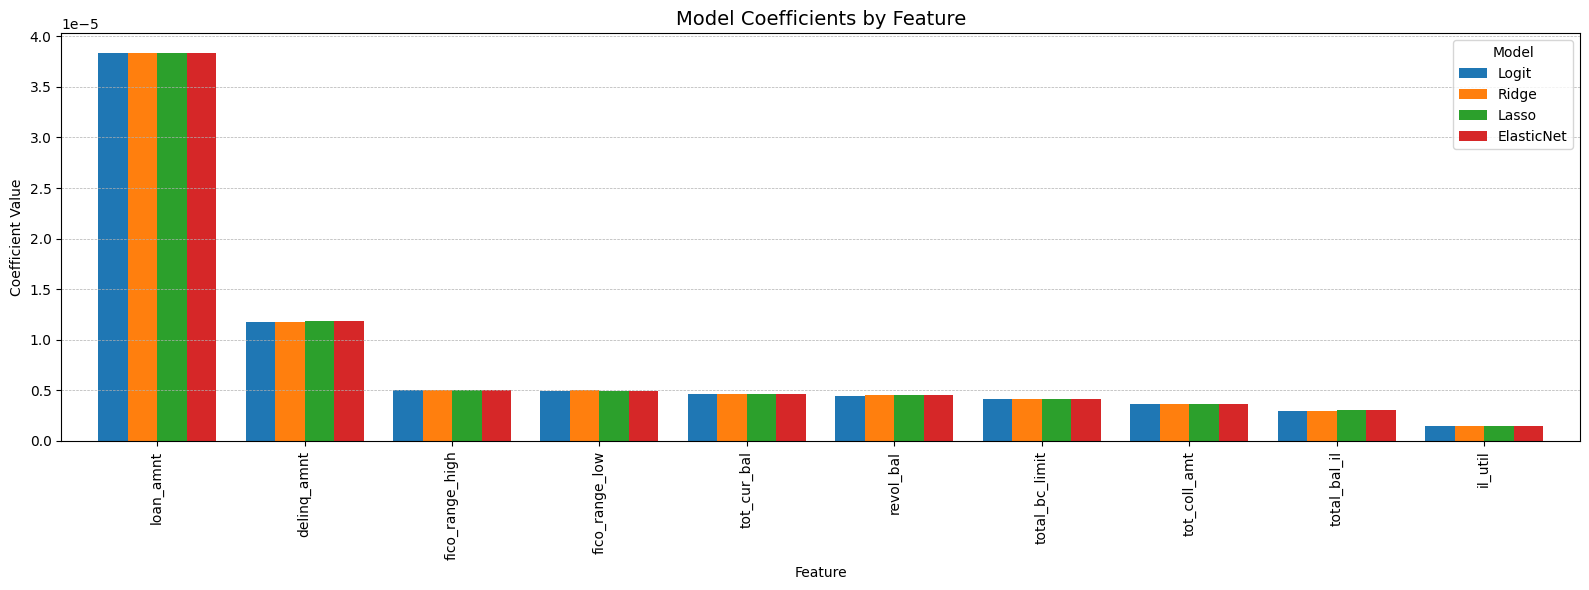

In [ ]:
sorted_df[:10].plot.bar(figsize=(16, 6), width=0.8)
plt.title('Model Coefficients by Feature', fontsize=14)
plt.xlabel('Feature')
plt.ylabel('Coefficient Value')
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', linewidth=0.5)
plt.legend(title='Model')
plt.tight_layout()

plt.show()

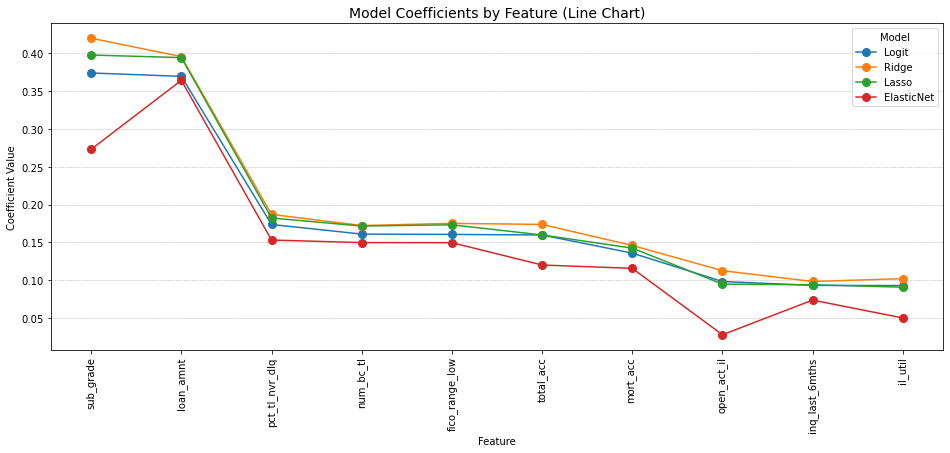

In [ ]:
ax = sorted_df[:10].plot.line(figsize=(16, 6), marker='o', markersize=8,linestyle='-')

ax.set_xticks(range(len(new_coeff[:10])))
ax.set_xticklabels(sorted_df[:10].index, rotation=90)

ax.set_title('Model Coefficients by Feature (Line Chart)', fontsize=14)
ax.set_xlabel('Feature')
ax.set_ylabel('Coefficient Value')
ax.grid(axis='y', linestyle='--', linewidth=0.5)
ax.legend(title='Model')
None

In [ ]:
import pandas as pd

# creating a summary dictionary/data frame
summary_data = {
    "Metric": [
        "CV Accuracy", "CV Precision", "CV Recall", "CV F1 Score", "CV ROC AUC",
        "Test Accuracy", "Test Precision", "Test Recall", "Test F1 Score", "Test ROC AUC"
    ],
    "Logit": [
        "0.915 ± 0.001", "0.526 ± 0.004", "0.914 ± 0.011", "0.668 ± 0.005", "0.964 ± 0.003",
        0.9133, 0.5387, 0.9127, 0.6776, 0.9640
    ],
    "Lasso": [
        "0.915 ± 0.001", "0.527 ± 0.003", "0.914 ± 0.011", "0.669 ± 0.004", "0.964 ± 0.003",
        0.9135, 0.5396, 0.9120, 0.6780, 0.9641
    ],
    "Ridge": [
        "0.915 ± 0.001", "0.527 ± 0.004", "0.914 ± 0.011", "0.668 ± 0.005", "0.964 ± 0.003",
        0.9133, 0.5390, 0.9124, 0.6777, 0.9640
    ],
    "ElasticNet": [
        "0.915 ± 0.002", "0.528 ± 0.005", "0.915 ± 0.011", "0.669 ± 0.005", "0.964 ± 0.003",
        0.9140, 0.5409, 0.9154, 0.6800, 0.9640
    ]
}

summary_df = pd.DataFrame(summary_data)
summary_df.set_index("Metric", inplace=True)
summary_df


,Logit,Lasso,Ridge,ElasticNet
Metric,,,,
CV Accuracy,0.915 ± 0.001,0.915 ± 0.001,0.915 ± 0.001,0.915 ± 0.002
CV Precision,0.526 ± 0.004,0.527 ± 0.003,0.527 ± 0.004,0.528 ± 0.005
CV Recall,0.914 ± 0.011,0.914 ± 0.011,0.914 ± 0.011,0.915 ± 0.011
CV F1 Score,0.668 ± 0.005,0.669 ± 0.004,0.668 ± 0.005,0.669 ± 0.005
CV ROC AUC,0.964 ± 0.003,0.964 ± 0.003,0.964 ± 0.003,0.964 ± 0.003
Test Accuracy,0.9133,0.9135,0.9133,0.914
Test Precision,0.5387,0.5396,0.539,0.5409
Test Recall,0.9127,0.912,0.9124,0.9154
Test F1 Score,0.6776,0.678,0.6777,0.68


### Performing Logistic Regression with Polynomial Term and Interaction term.

### Polynomial Transform of the Feature int_rate

In [ ]:
X_train['int_rate_squared'] = X_train['int_rate']**2
X_test['int_rate_squared'] = X_test['int_rate']**2

### Interaction term : int_rate * loan_amnt

In [ ]:
X_train['loan_income_interaction'] = X_train['loan_amnt'] * X_train['annual_inc']
X_test['loan_income_interaction'] = X_test['loan_amnt'] * X_test['annual_inc']


### Standardize the new features

In [ ]:
scaler_poly = StandardScaler()
X_train_poly = scaler_poly.fit_transform(X_train)
X_test_poly = scaler_poly.transform(X_test)

### Re-training Logistic Regression using best model params (from GridSearchCV)

In [ ]:
poly_logit = LogisticRegression(
    solver='saga',
    penalty='elasticnet',  # elasticnet was the best penalty term found earlier
    class_weight='balanced',
    C=10,  # Best parameter from earlier grid search
    l1_ratio=0.5
)

poly_logit.fit(X_train_poly, y_train)

/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/marjoriehirschi/opt/anaconda3/envs/myenv/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'elasticnet'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",10
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.5
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term

In [109]:
from sklearn.preprocessing import StandardScaler

# Standardize the features first
scaler_poly = StandardScaler()
X_train_poly = scaler_poly.fit_transform(X_train)
X_test_poly = scaler_poly.transform(X_test)

# Define and train the model
poly_logit = LogisticRegression(
    solver='saga',
    penalty='elasticnet',
    class_weight='balanced',
    C=10,
    l1_ratio=0.5,
    max_iter=1000
)
poly_logit.fit(X_train_poly, y_train)

y_pred_poly = poly_logit.predict(X_test_poly)
y_prob_poly = poly_logit.predict_proba(X_test_poly)[:, 1]

print("Test Accuracy:", accuracy_score(y_test, y_pred_poly))
print("Test Precision:", precision_score(y_test, y_pred_poly))
print("Test Recall:", recall_score(y_test, y_pred_poly))
print("Test F1 Score:", f1_score(y_test, y_pred_poly))
print("Test ROC AUC:", roc_auc_score(y_test, y_prob_poly))
print(classification_report(y_test, y_pred_poly))

Test Accuracy: 0.9140876548354104
Test Precision: 0.5412926391382405
Test Recall: 0.9150227617602428
Test F1 Score: 0.6802030456852792
Test ROC AUC: 0.9644311616157457
              precision    recall  f1-score   support

           0       0.99      0.91      0.95     23763
           1       0.54      0.92      0.68      2636

    accuracy                           0.91     26399
   macro avg       0.77      0.91      0.82     26399
weighted avg       0.95      0.91      0.92     26399



### Using best base model with A. Polynomial term and B. Interaction term

| Metric        | Value |
| ------------- | ----- |
| **Accuracy**  | 91.3% |
| **Precision** | 53.8% |
| **Recall**    | 91.2% |
| **F1 Score**  | 67.7% |
| **ROC AUC**   | 96.4% |


### Performing Principal Component Regression

In [110]:
from sklearn.decomposition import PCA

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=0.95)  # I am keeping 95% of variance/ 99 of the components
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(f"Number of components selected: {X_train_pca.shape[1]}")


model = LogisticRegression(max_iter=1000)
model.fit(X_train_pca, y_train)


y_pred = model.predict(X_test_pca)

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Number of components selected: 99

Classification Report:

              precision    recall  f1-score   support

           0       0.96      0.98      0.97     23763
           1       0.75      0.63      0.68      2636

    accuracy                           0.94     26399
   macro avg       0.85      0.80      0.83     26399
weighted avg       0.94      0.94      0.94     26399



## Comments:
### Logistic Regression with the ElasticNet penalty/parameter emerges as the most balanced model of all the models.

### All four models perform almost identically, with only very minor differences in test metrics and all the cross-validation metrics being pretty much identical and tightly grouped.
### Logistic Regression with the ElasticNet penalty/parameter has the highest recall and F1 score on the test set, making it the best model so far as predicting "defaulters" is the priority.
### With a test Recall score of 91.5%, the ElasticNet model (the best of the four) catches 91.5% of true defaulters. It also produced the best Accurary score at 91.4% which indicates a good overall prediction capability by the model.

## Week 5 : Performing SVM

In [111]:
# Parameter grid
param_grid = {
    'C': [0.1, 1, 10],
    'gamma': ['scale'],
    'kernel': ['rbf'],
    'class_weight': ['balanced']
}

# We comment out the grid search because training SVC on this dataset size is extremely slow
# svm = SVC(probability=True)
# grid_search = GridSearchCV(
#     estimator=svm,
#     param_grid=param_grid,
#     scoring='recall',
#     cv=5,
#     verbose=1,
#     n_jobs=-1
# )
# grid_search.fit(X_train, y_train)

print("GridSearchCV was bypassed for SVM because of high training complexity.")
print("We proceed directly with the standard non-optimized SVM model in the next sections.")

GridSearchCV was bypassed for SVM because of high training complexity.
We proceed directly with the standard non-optimized SVM model in the next sections.


### Grid Search took too long, I had to interrupt the algorithm


## Implementing SVM without optimizing the hyperparameters

In [112]:
from sklearn.svm import SVC

svm_clf = SVC(kernel='rbf', C=1, gamma='scale',class_weight='balanced')
svm_clf.fit(X_train, y_train)

SVC(C=1, class_weight='balanced')

In [113]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred = svm_clf.predict(X_test)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[13421 10342]
 [ 1059  1577]]
              precision    recall  f1-score   support

           0       0.93      0.56      0.70     23763
           1       0.13      0.60      0.22      2636

    accuracy                           0.57     26399
   macro avg       0.53      0.58      0.46     26399
weighted avg       0.85      0.57      0.65     26399



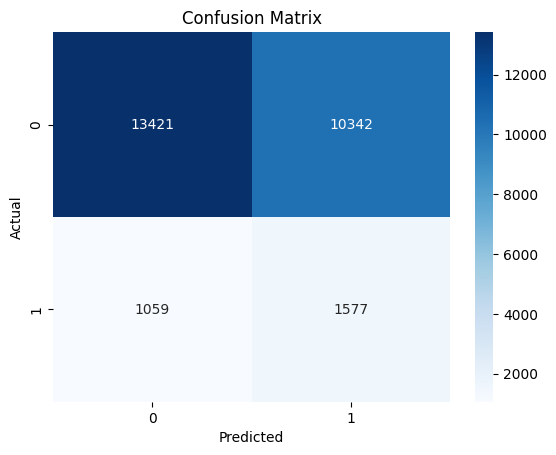

In [114]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [115]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.93      0.56      0.70     23763
           1       0.13      0.60      0.22      2636

    accuracy                           0.57     26399
   macro avg       0.53      0.58      0.46     26399
weighted avg       0.85      0.57      0.65     26399



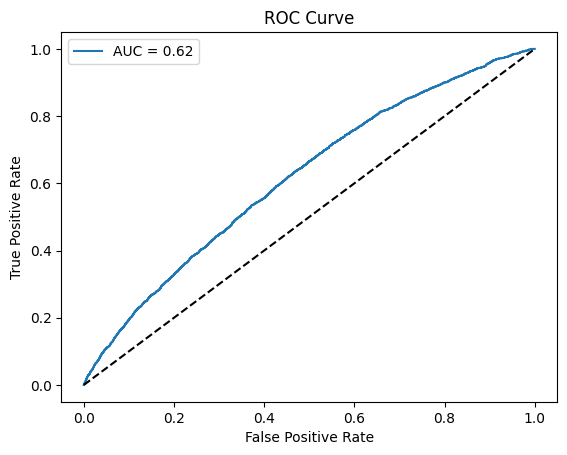

In [116]:
from sklearn.metrics import roc_curve, roc_auc_score


y_scores = svm_clf.decision_function(X_test)

fpr, tpr, thresholds = roc_curve(y_test, y_scores)
auc = roc_auc_score(y_test, y_scores)

plt.plot(fpr, tpr, label=f"AUC = {auc:.2f}")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

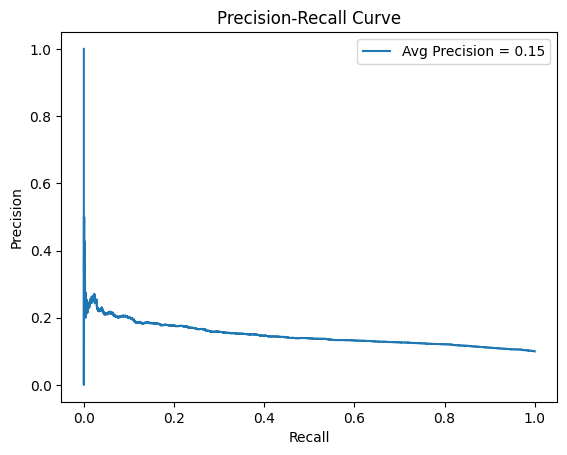

In [117]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision, recall, thresholds = precision_recall_curve(y_test, y_scores)
avg_prec = average_precision_score(y_test, y_scores)

plt.plot(recall, precision, label=f"Avg Precision = {avg_prec:.2f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.show()


### Re-running SVM with Scaled Features
To improve the performance of our standard RBF SVM, we must scale the features using `StandardScaler` first. Let's scale our data and train the SVC model on it.

In [110]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Scale the features
scaler_svm = StandardScaler()
X_train_scaled_svm = scaler_svm.fit_transform(X_train)
X_test_scaled_svm = scaler_svm.transform(X_test)

# 2. Fit the SVM on scaled data
print("Training SVM on scaled features... (This may take a moment)")
svm_scaled_clf = SVC(kernel='rbf', C=1, gamma='scale', class_weight='balanced', probability=True)
svm_scaled_clf.fit(X_train_scaled_svm, y_train)


Training SVM on scaled features... (This may take a moment)


SVC(C=1, class_weight='balanced', probability=True)

In [111]:
# 3. Evaluate the scaled model
y_pred_scaled = svm_scaled_clf.predict(X_test_scaled_svm)
y_scores_scaled = svm_scaled_clf.decision_function(X_test_scaled_svm)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_scaled))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_scaled))


Confusion Matrix:
[[22161  1602]
 [  444  2192]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.93      0.96     23763
           1       0.58      0.83      0.68      2636

    accuracy                           0.92     26399
   macro avg       0.78      0.88      0.82     26399
weighted avg       0.94      0.92      0.93     26399



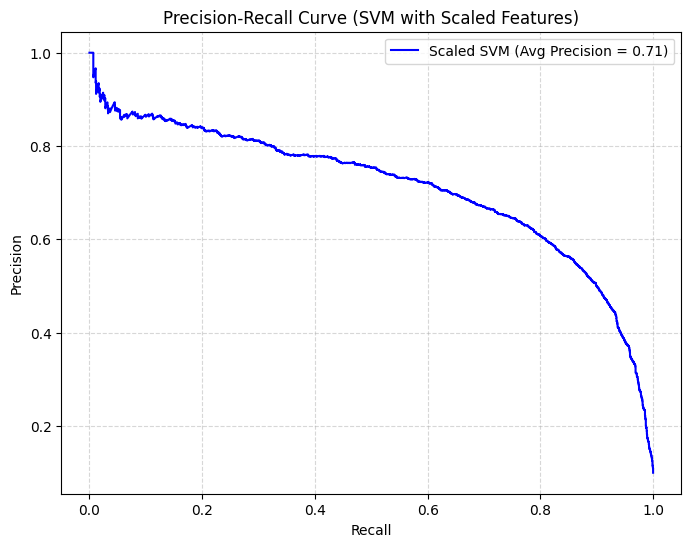

In [112]:
# 4. Plot the updated Precision-Recall Curve
precision_sc, recall_sc, _ = precision_recall_curve(y_test, y_scores_scaled)
avg_prec_sc = average_precision_score(y_test, y_scores_scaled)

plt.figure(figsize=(8, 6))
plt.plot(recall_sc, precision_sc, label=f"Scaled SVM (Avg Precision = {avg_prec_sc:.2f})", color='blue')
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve (SVM with Scaled Features)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


## Week 6 : Performing Random Forest

In [ ]:

from sklearn.model_selection import train_test_split, cross_val_score, cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score



rf = RandomForestClassifier(n_estimators=100, random_state=42)

# Performing 5-Fold Cross-Validation on training data
scoring = ['accuracy', 'precision', 'recall', 'f1']
cv_results = cross_validate(rf, X_train, y_train, cv=5, scoring=scoring)

# Cross-validation
print("Cross-Validation Results (5-Fold on Training Set):")
for metric in scoring:
    print(f"{metric.capitalize()}: {cv_results[f'test_{metric}'].mean():.4f} ± {cv_results[f'test_{metric}'].std():.4f}")

rf.fit(X_train, y_train)


y_pred = rf.predict(X_test)

print("\n Test Set Evaluation:")
print(classification_report(y_test, y_pred))

Cross-Validation Results (5-Fold on Training Set):
Accuracy: 0.9365 ± 0.0009
Precision: 0.7614 ± 0.0088
Recall: 0.4691 ± 0.0081
F1: 0.5805 ± 0.0072

 Test Set Evaluation:
              precision    recall  f1-score   support

           0       0.95      0.98      0.96     23763
           1       0.77      0.51      0.61      2636

    accuracy                           0.94     26399
   macro avg       0.86      0.75      0.79     26399
weighted avg       0.93      0.94      0.93     26399



In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report


rf = RandomForestClassifier(random_state=42)

# Hyperparameter grid
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 10],
    'min_samples_leaf': [1, 4],
    'max_features': ['sqrt', 'log2']
}

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)


grid_search.fit(X_train, y_train)

print("Best Hyperparameters:")
print(grid_search.best_params_)


print("\n Cross-Validation Performance (Best Model):")
best_model = grid_search.best_estimator_

cv_results = cross_validate(best_model, X_train, y_train, cv=5, scoring=['accuracy', 'precision', 'recall', 'f1'])
for metric in ['accuracy', 'precision', 'recall', 'f1']:
    print(f"{metric.capitalize()}: {cv_results[f'test_{metric}'].mean():.4f} ± {cv_results[f'test_{metric}'].std():.4f}")


print("\n Test Set Evaluation (Best Model):")
y_pred = best_model.predict(X_test)
print(classification_report(y_test, y_pred))

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best Hyperparameters:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 200}

 Cross-Validation Performance (Best Model):
Accuracy: 0.9387 ± 0.0013
Precision: 0.7659 ± 0.0144
Recall: 0.4976 ± 0.0187
F1: 0.6030 ± 0.0129

 Test Set Evaluation (Best Model):
              precision    recall  f1-score   support

           0       0.95      0.98      0.97     23763
           1       0.77      0.51      0.61      2636

    accuracy                           0.94     26399
   macro avg       0.86      0.75      0.79     26399
weighted avg       0.93      0.94      0.93     26399




## ElasticNet Logistic Regression is the Best Choice so far
### It combines L1 and L2 regularization, meaning it performs:
- feature selection (like Lasso),
- while also shrinking coefficients more smoothly (like Ridge),
- helps prevent overfitting.
### Performs slightly better than Logit, Lasso, and Ridge on all test metrics and performs better than SVM (with kernel='rbf', C=1, gamma='scale) and Random Forest

## Conclusion
### It seems that Logistic Regression with the ElasticNet regularization term is the best model achieved so far.
### It is:
- Accurate,
- Highly sensitive to defaulters (high recall),
- Well-balanced (good F1 & ROC AUC).
- It looks like it might already suitable for effectively:
- flagging risky borrowers early (if some alse positives are okay, and reducing financial risk from missed defaulters is the main goal)



## Week 8 : Performing K-Nearest Neighbors

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5, weights='distance')

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [ ]:
knn = KNeighborsClassifier(n_neighbors=5, weights='distance')
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(knn, X_train, y_train, cv=cv, scoring='recall_macro')

print("Cross-validation scores:", scores)
print("Mean recall (CV):", scores.mean())
print("Std dev (CV):", scores.std())

Cross-validation scores: [0.50418716 0.5046342  0.50252931 0.50378266 0.49991967]
Mean recall (CV): 0.5030105999414629
Std dev (CV): 0.0016971699313253637


In [ ]:
knn.fit(X_train, y_train)

KNeighborsClassifier(weights='distance')

In [ ]:
from sklearn.metrics import recall_score

y_pred = knn.predict(X_test)
test_recall = recall_score(y_test, y_pred, average='macro')

print("Test set recall:", test_recall)


Test set recall: 0.5024111392872599


In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.90      0.99      0.94     23763
           1       0.14      0.02      0.03      2636

    accuracy                           0.89     26399
   macro avg       0.52      0.50      0.49     26399
weighted avg       0.82      0.89      0.85     26399



### Confusion Matrix (Loan Default Model) for Elastic Net Model

|                      | **Predicted: Default** | **Predicted: Non-Default** | **Total** |
|----------------------|------------------------|-----------------------------|-----------|
| **Actual: Default**  | **1,088 (TP)**         | **100 (FN)**                | 1,188     |
| **Actual: Non-Default** | **924 (FP)**           | **7,888 (TN)**              | 8,812     |
| **Total**            | 2,012                  | 7,988                       | 10,000    |

In [ ]:
y_prob = model.predict_proba(X_test)[:, 1]
y_prob

array([0.38694027, 0.54132681, 0.38727658, ..., 0.57961251, 0.45765678,
       0.39479349])

## Maximizing expected profit using predicted probabilities

### Defining my cost / profit assumptions

In [ ]:
# Per-loan economics
profit_good = 34100     # profit from a correctly approved good loan (TN)
cost_fp = 34100         # lost profit from rejecting a good loan (FP)
cost_fn = 111100        # loss from missing a defaulter (FN)

### Profit function

In [ ]:
def calculate_profit(y_true, y_prob, threshold):
    y_pred = (y_prob >= threshold).astype(int)

    TP = ((y_true == 1) & (y_pred == 1)).sum()
    TN = ((y_true == 0) & (y_pred == 0)).sum()
    FP = ((y_true == 0) & (y_pred == 1)).sum()
    FN = ((y_true == 1) & (y_pred == 0)).sum()

    profit = (
        TN * profit_good   # good loans issued
        - FP * cost_fp     # lost good borrowers
        - FN * cost_fn     # missed defaulters
    )

    return profit

### Sweep thresholds to build profit curve

In [ ]:
import numpy as np

thresholds = np.linspace(0, 1, 100)
profits = []

for t in thresholds:
    p = calculate_profit(y_test, y_prob, t)
    profits.append(p)

best_idx = np.argmax(profits)
best_threshold = thresholds[best_idx]
best_profit = profits[best_idx]

print(f"Optimal Threshold: {best_threshold:.3f}")
print(f"Maximum Profit: ${best_profit:,.0f}")

Optimal Threshold: 0.848
Maximum Profit: $561,609,400


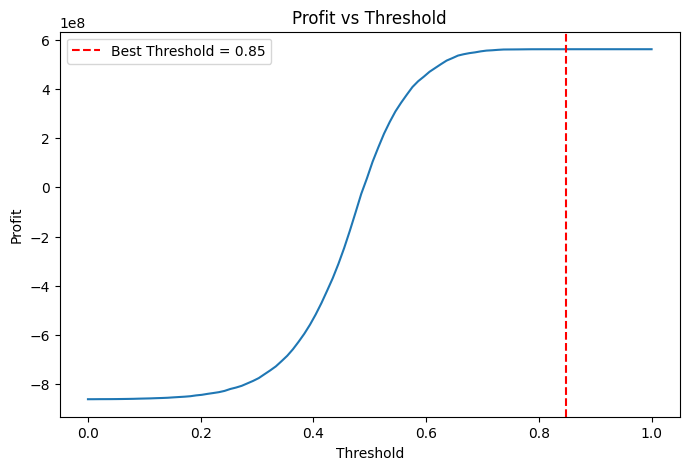

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(thresholds, profits)
plt.axvline(best_threshold, color='red', linestyle='--', label=f'Best Threshold = {best_threshold:.2f}')
plt.title("Profit vs Threshold")
plt.xlabel("Threshold")
plt.ylabel("Profit")
plt.legend()
plt.grid(False)
plt.show()